# Reimplementasi Klasifikasi Penyakit Daun Cabai Menggunakan GLCM, Seleksi Fitur, dan Support Vector Machine (SVM)
## Perbandingan Performa dengan Model Baseline MobileNet (Putri dkk., 2025)

---

### A. Judul dan Identitas Penelitian

- **Judul Penelitian**: Reimplementasi Klasifikasi Penyakit Daun Cabai Menggunakan Kombinasi *Gray-Level Co-occurrence Matrix* (GLCM), Seleksi Fitur ANOVA F-test, dan *Support Vector Machine* (SVM) serta Perbandingannya dengan MobileNet.
- **Tujuan Eksperimen**:
  1. Mengimplementasikan alur ekstraksi fitur tekstur GLCM (multi-sudut $0^\circ, 45^\circ, 90^\circ, 135^\circ$), seleksi fitur terarah (ANOVA F-test), dan klasifikasi SVM pada dataset penyakit daun cabai.
  2. Menggunakan **pembagian dataset bawaan Roboflow** (`train/`, `valid/`, `test/`) tanpa menggabungkan atau melakukan re-split manual.
  3. Mengevaluasi secara objektif dampak tahap **seleksi fitur** dengan membandingkan **Model A (GLCM + SVM tanpa seleksi fitur)** vs **Model B (GLCM + Seleksi Fitur + SVM)**.
  4. Membandingkan hasil performa GLCM-SVM dengan baseline model CNN/MobileNet dari penelitian terdahulu oleh **Putri dkk. (2025)** yang menggunakan dataset Roboflow `chili-futhd` yang sama.
  5. Menyediakan eksperimen yang **terstruktur, bebas data leakage, reproducible**, dan siap dipertanggungjawabkan dalam naskah akademik/skripsi.
- **Dataset**: Roboflow **Chili Leaves Disease Classification (`chili-futhd`)** – Subset 5 Kelas (*Healthy, Leaf curl, Leaf spot, Whitefly, Yellowish*). Kelas *Powdery mildew* dikeluarkan dari eksperimen utama sesuai batasan penelitian.
- **Metode Utama**: `Preprocessing Citra` $\rightarrow$ `Ekstraksi Fitur GLCM (30 fitur)` $\rightarrow$ `Analisis Korelasi` $\rightarrow$ `StandardScaler` (fit pada train) $\rightarrow$ `Seleksi Fitur ANOVA F-test (k=15, fit pada train)` $\rightarrow$ `SVM (RBF Kernel + GridSearchCV 5-Fold Stratified CV pada train)`.

---

### Referensi Utama

1. **Jurnal 1 (Sumber Dataset & Baseline Pembanding CNN/MobileNet)**:
   - **Penulis**: Liza Puspita Putri, Muhammad Rafi Muttaqin, Yudhi Raymond Ramadhan (2025).
   - **Judul**: *Klasifikasi Penyakit Daun Cabai Menggunakan Model MobileNet*.
   - **Jurnal**: TeknoIS: Jurnal Ilmiah Teknologi Informasi dan Sains, Vol. 15 No. 1, 2025, hlm. 74–86.
   - **URL Dataset**: [https://universe.roboflow.com/chili-leaves-disease-classification/chili-futhd/dataset/1](https://universe.roboflow.com/chili-leaves-disease-classification/chili-futhd/dataset/1)
   - **Peran**: Acuan sumber dataset asli (6 kelas) dan baseline hasil akurasi model MobileNet ($84.84\% / 84.85\%$).

2. **Jurnal 2 (Acuan Metode GLCM & SVM)**:
   - **Judul**: *Deteksi Penyakit Daun Cabai Menggunakan Kombinasi GLCM dan HSV dengan Klasifikasi SVM*.
   - **Jurnal**: INSECT (Informatics and Security): Jurnal Teknik Informatika, Vol. 11 No. 2, 2025, hlm. 178–189.
   - **Peran**: Acuan pendekatan ekstraksi fitur tekstur GLCM dan pemodelan klasifikasi SVM.

---

### Struktur Notebook

| No | Bagian yang Diminta | Section |
|---:|---|---|
| 1 | Judul | A |
| 2 | Tujuan penelitian | A |
| 3 | Dataset | C |
| 4 | Pemeriksaan dataset | C |
| 5 | Distribusi kelas | C, D |
| 6 | Preprocessing | F |
| 7 | Ekstraksi GLCM | F |
| 8 | Analisis fitur | G |
| 9 | Feature Selection ANOVA | H |
| 10 | Model A — GLCM + SVM | I |
| 11 | Model B — GLCM + Feature Selection + SVM | I |
| 12 | Evaluasi | J, K, L |
| 13 | External Testing (opsional) | M |
| 14 | Perbandingan dengan MobileNet | N |
| 15 | Pembahasan | O |
| 16 | Kesimpulan | P |
| — | Dokumentasi reproducibility (pendukung) | Q |


In [1]:
# B. Import Library

import os
import sys
import time
import zipfile
import warnings
warnings.filterwarnings('ignore')

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Library tambahan untuk pencatatan versi (reproducibility)
import sklearn
import skimage
import matplotlib

# Library Scikit-Image untuk GLCM
from skimage.feature import graycomatrix, graycoprops

# Library Scikit-Learn untuk Machine Learning & Evaluasi
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    precision_recall_fscore_support, classification_report, confusion_matrix
)

# Konfigurasi Tampilan Plot
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10

print("Semua library berhasil di-import!")
print(f"Python Version: {sys.version.split()[0]}")
print(f"NumPy Version: {np.__version__}")
print(f"Pandas Version: {pd.__version__}")
print(f"OpenCV Version: {cv2.__version__}")
print(f"scikit-learn Version: {sklearn.__version__}")
print(f"scikit-image Version: {skimage.__version__}")
print(f"Matplotlib Version: {matplotlib.__version__}")
print(f"Seaborn Version: {sns.__version__}")


Semua library berhasil di-import!
Python Version: 3.10.11
NumPy Version: 2.2.6
Pandas Version: 2.3.0
OpenCV Version: 5.0.0
scikit-learn Version: 1.7.0
scikit-image Version: 0.25.2
Matplotlib Version: 3.10.3
Seaborn Version: 0.13.2


### C. Load dan Pemeriksaan Dataset Bawaan

Pada tahap ini, dataset Roboflow `chili-futhd` dimuat langsung menggunakan struktur folder bawaan:
- `./dataset/train/`
- `./dataset/valid/`
- `./dataset/test/`

**Penting**: Pembagian dataset asli dari Roboflow dipertahankan secara utuh tanpa melakukan penggabungan citra atau split ulang (no re-splitting / no data leakage).


In [2]:
zip_path = r'C:\Users\maull\Downloads\Kuliah\SMT 7\Bimbingan TA\Chili.v1i.folder.zip'
dataset_dir = './dataset'

# Ekstrak zip jika folder belum ada
if not os.path.exists(dataset_dir) or len(os.listdir(dataset_dir)) == 0:
    print("Mengekstrak dataset dari ZIP...")
    os.makedirs(dataset_dir, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(dataset_dir)
    print("Ekstraksi selesai!")

print(f"Path Dataset Utama: {os.path.abspath(dataset_dir)}")
print(f"Isi Direktori Utama: {os.listdir(dataset_dir)}")

# Data discovery untuk seluruh 6 kelas asli
all_image_records = []
splits = ['train', 'valid', 'test']

for split in splits:
    split_path = os.path.join(dataset_dir, split)
    if os.path.exists(split_path):
        for class_name in os.listdir(split_path):
            class_path = os.path.join(split_path, class_name)
            if os.path.isdir(class_path):
                for fname in os.listdir(class_path):
                    if fname.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
                        fpath = os.path.join(class_path, fname)
                        all_image_records.append({
                            'filename': fname,
                            'filepath': fpath,
                            'split': split,
                            'class_name': class_name
                        })

df_raw_images = pd.DataFrame(all_image_records)
print(f"Total Citra Ditemukan dalam Dataset (6 Kelas Asli): {len(df_raw_images)}")

# Periksa integritas gambar (corrupted check & format check)
corrupted_count = 0
resolutions = set()

for fpath in df_raw_images['filepath']:
    img = cv2.imread(fpath)
    if img is None:
        corrupted_count += 1
    else:
        resolutions.add(img.shape)

print(f"Jumlah Gambar Rusak / Tidak Dapat Dibaca: {corrupted_count}")
print(f"Resolusi Citra Asli yang Ditemukan (H, W, C): {resolutions}")

# Tabel Distribusi Dataset Asli (6 Kelas Bawaan)
df_dist_raw = df_raw_images.groupby(['class_name', 'split']).size().unstack(fill_value=0)[['train', 'valid', 'test']]
df_dist_raw['Total'] = df_dist_raw.sum(axis=1)
print("\n--- Tabel Distribusi Citra Dataset Asli (6 Kelas Bawaan) ---")
display(df_dist_raw)


Path Dataset Utama: C:\Users\maull\Downloads\Kuliah\SMT 7\Bimbingan TA\reimplementasi jurnal klasifikasi\dataset
Isi Direktori Utama: ['README.dataset.txt', 'README.roboflow.txt', 'test', 'train', 'valid']
Total Citra Ditemukan dalam Dataset (6 Kelas Asli): 1147


Jumlah Gambar Rusak / Tidak Dapat Dibaca: 0
Resolusi Citra Asli yang Ditemukan (H, W, C): {(640, 640, 3)}

--- Tabel Distribusi Citra Dataset Asli (6 Kelas Bawaan) ---


split,train,valid,test,Total
class_name,,,,
healthy,121,33,21,175
leaf curl,151,48,23,222
leaf spot,180,38,20,238
powdery mildew,87,35,14,136
whitefly,128,30,20,178
yellowish,133,48,17,198


### D. Seleksi Lima Kelas Sesuai Batasan Penelitian

Sesuai rancangan penelitian dan batasan masalah:
- **5 Kelas yang Digunakan**: `Healthy`, `Leaf curl`, `Leaf spot`, `Whitefly`, `Yellowish`.
- **Kelas yang Dikeluarkan**: `Powdery mildew` (136 citra secara keseluruhan).

*Catatan Metodologis*: Mengeluarkan kelas Powdery mildew merupakan keputusan pembatasan ruang lingkup penelitian (subset 5 kelas) untuk menyelaraskan dengan fokus analisis penyakit daun utama. Dataset Roboflow asli tetap diakui memiliki 6 kelas.


Total Citra Setelah Filtering (5 Kelas): 1011 citra

--- Tabel Distribusi Citra 5 Kelas Sesuai Folder Bawaan ---


split,train,valid,test,Total
class_name,,,,
healthy,121,33,21,175
leaf curl,151,48,23,222
leaf spot,180,38,20,238
whitefly,128,30,20,178
yellowish,133,48,17,198


Ringkasan Total Citra Per-Split (5 Kelas):
  - Folder train:  713 citra (70.52%)
  - Folder valid:  197 citra (19.49%)
  - Folder test :  101 citra (9.99%)


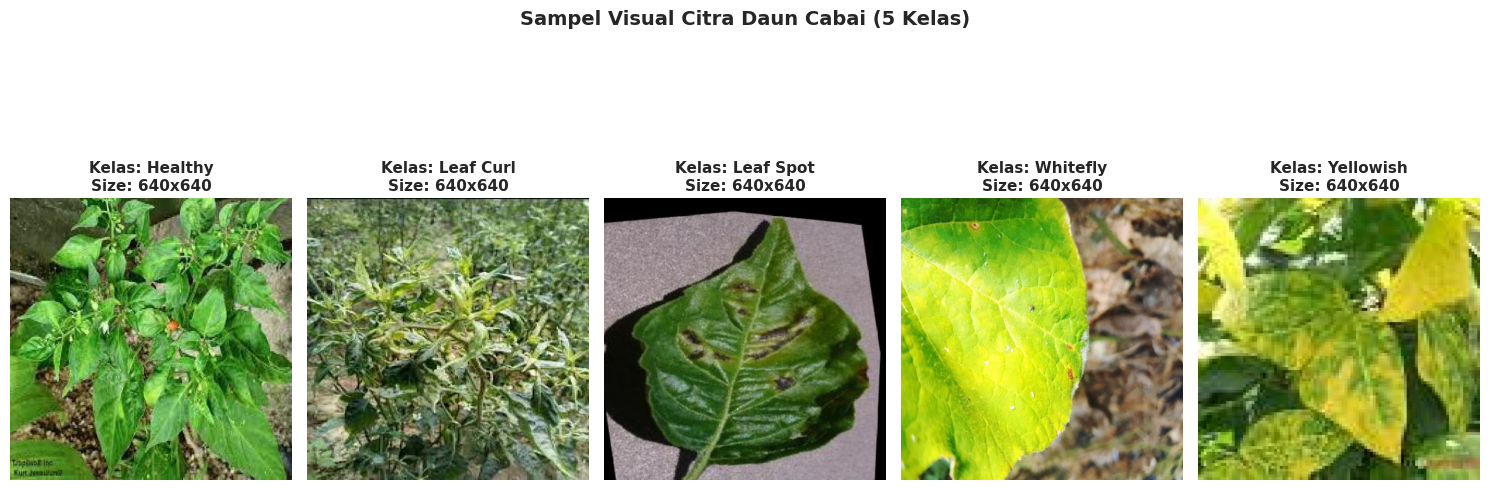

In [3]:
target_classes_5 = ['healthy', 'leaf curl', 'leaf spot', 'whitefly', 'yellowish']

df_5class = df_raw_images[df_raw_images['class_name'].isin(target_classes_5)].copy().reset_index(drop=True)

print(f"Total Citra Setelah Filtering (5 Kelas): {len(df_5class)} citra")

# Tabel Distribusi 5 Kelas Bawaan Per-Split
df_dist_5 = df_5class.groupby(['class_name', 'split']).size().unstack(fill_value=0)[['train', 'valid', 'test']]
df_dist_5['Total'] = df_dist_5.sum(axis=1)
print("\n--- Tabel Distribusi Citra 5 Kelas Sesuai Folder Bawaan ---")
display(df_dist_5)

# Tampilkan ringkasan total citra per split
print("Ringkasan Total Citra Per-Split (5 Kelas):")
for split_name in ['train', 'valid', 'test']:
    cnt = len(df_5class[df_5class['split'] == split_name])
    pct = (cnt / len(df_5class)) * 100
    print(f"  - Folder {split_name:5s}: {cnt:4d} citra ({pct:.2f}%)")

# Visualisasi Contoh Gambar untuk Setiap Kelas
plt.figure(figsize=(15, 6))
for idx, cname in enumerate(target_classes_5):
    sample_row = df_5class[df_5class['class_name'] == cname].iloc[0]
    img_bgr = cv2.imread(sample_row['filepath'])
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    plt.subplot(1, 5, idx + 1)
    plt.imshow(img_rgb)
    plt.title(f"Kelas: {cname.title()}\nSize: {img_bgr.shape[0]}x{img_bgr.shape[1]}", fontsize=11, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.suptitle("Sampel Visual Citra Daun Cabai (5 Kelas)", fontsize=14, fontweight='bold', y=1.05)
plt.show()


### E. Pencegahan Data Leakage (Strict Folder Isolation)

Untuk memastikan keabsahan sound metodologi dan mencegah **data leakage**:

1. **Pembagian Dataset Bawaan**:
   - **Training Set (`train/`)**: 713 citra ($70.52\%$)
   - **Validation Set (`valid/`)**: 197 citra ($19.49\%$)
   - **Test Set (`test/`)**: 101 citra ($9.99\%$)
2. **Aturan Pembelajaran Parameter**:
   - `StandardScaler` di-fit **HANYA** pada Training Set (`train/`), kemudian di-transform ke Validation Set (`valid/`) dan Test Set (`test/`).
   - `StandardScaler` di-fit lebih dahulu, lalu `SelectKBest` (ANOVA F-test) di-fit **HANYA** pada Training Set (`train/`) yang sudah terstandardisasi.
   - `GridSearchCV` & SVM di-fit **HANYA** pada Training Set (`train/`) menggunakan 5-Fold Stratified Cross-Validation.
   - Validation Set (`valid/`) dan Test Set (`test/`) sepenuhnya diisolasi dan tidak digunakan dalam pembelajaran parameter.


### F. Preprocessing Citra dan Ekstraksi Fitur GLCM Multi-Angle

#### 1. Preprocessing Citra:
- **Resizing**: Mengubah ukuran citra menjadi $128 \times 128$ piksel agar konsisten.
- **Grayscale Conversion**: Konversi dari BGR ke Grayscale (`cv2.COLOR_BGR2GRAY`).
  - *Alasan Metodologis*: GLCM (*Gray-Level Co-occurrence Matrix*) beroperasi pada matriks frekuensi kemunculan pasangan derajat keabuan piksel tetangga. Konversi ke grayscale menghilangkan informasi warna yang redundan untuk analisis tekstur murni, mereduksi kompleksitas komputasi, dan menyelaraskan dengan landasan teori Haralick (1973).

#### 2. Parameter GLCM Multi-Angle:
- **Distance ($d$)**: $1$ piksel (piksel tetangga langsung).
- **Angles (Sudut $\theta$)**: $0^\circ, 45^\circ, 90^\circ, 135^\circ$ (dalam radian: $0, \pi/4, \pi/2, 3\pi/4$).
- **Levels**: $256$ tingkat keabuan.
- **Symmetric**: `True`, **Normed**: `True`.
- **Properti Haralick yang Diekstrak**: `Contrast`, `Dissimilarity`, `Homogeneity`, `Energy`, `Correlation`, `ASM`.
- **Strategi Multi-Angle**: Untuk setiap citra, diekstrak 24 fitur sudut individu ($4 \text{ sudut} \times 6 \text{ properti}$) ditambah 6 fitur rata-rata sudut (`mean`), menghasilkan **30 fitur tekstur GLCM**.


In [4]:
angles_deg = [0, 45, 90, 135]
angles_rad = [0, np.pi/4, np.pi/2, 3*np.pi/4]
props = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']

def extract_glcm_features_from_df(df_subset):
    feature_rows = []
    for idx, row in df_subset.iterrows():
        fpath = row['filepath']
        label = row['class_name']
        split_name = row['split']
        
        img_bgr = cv2.imread(fpath)
        if img_bgr is None:
            continue
        
        # Preprocessing: Grayscale & Resize 128x128
        img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
        img_gray = cv2.resize(img_gray, (128, 128))
        
        # Ekstraksi GLCM
        glcm = graycomatrix(img_gray, distances=[1], angles=angles_rad, levels=256, symmetric=True, normed=True)
        
        row_dict = {
            'Image': row['filename'],
            'Class': label,
            'Split': split_name
        }
        
        for prop in props:
            vals = graycoprops(glcm, prop)[0] # 4 nilai untuk 4 sudut
            for i, deg in enumerate(angles_deg):
                row_dict[f'{prop}_{deg}deg'] = vals[i]
            row_dict[f'{prop}_mean'] = np.mean(vals)
            
        feature_rows.append(row_dict)
        
    return pd.DataFrame(feature_rows)

print("Mulai Ekstraksi Fitur GLCM Berdasarkan Folder Bawaan...")
start_t = time.time()

df_features_train = extract_glcm_features_from_df(df_5class[df_5class['split'] == 'train'])
df_features_val   = extract_glcm_features_from_df(df_5class[df_5class['split'] == 'valid'])
df_features_test  = extract_glcm_features_from_df(df_5class[df_5class['split'] == 'test'])

print(f"Ekstraksi Fitur Selesai dalam {time.time() - start_t:.2f} detik!")
print(f"Ukuran Matriks Fitur Training (`train/`) : {df_features_train.shape}")
print(f"Ukuran Matriks Fitur Validation (`valid/`) : {df_features_val.shape}")
print(f"Ukuran Matriks Fitur Test (`test/`)       : {df_features_test.shape}")

print("\n--- Contoh Matriks Fitur GLCM (5 Baris Pertama Data Training) ---")
display(df_features_train.head())


Mulai Ekstraksi Fitur GLCM Berdasarkan Folder Bawaan...


Ekstraksi Fitur Selesai dalam 21.73 detik!
Ukuran Matriks Fitur Training (`train/`) : (713, 33)
Ukuran Matriks Fitur Validation (`valid/`) : (197, 33)
Ukuran Matriks Fitur Test (`test/`)       : (101, 33)

--- Contoh Matriks Fitur GLCM (5 Baris Pertama Data Training) ---


,Image,Class,Split,contrast_0deg,contrast_45deg,contrast_90deg,contrast_135deg,contrast_mean,dissimilarity_0deg,dissimilarity_45deg,...,correlation_0deg,correlation_45deg,correlation_90deg,correlation_135deg,correlation_mean,ASM_0deg,ASM_45deg,ASM_90deg,ASM_135deg,ASM_mean
0,Cabai-sehat011_jpg.rf.932c7c41e3396f03b06bdb66...,healthy,train,1127.660864,1426.810156,1021.173474,1420.769546,1249.103510,23.175135,26.517391,...,0.682523,0.598306,0.712324,0.599947,0.648275,0.000109,0.000100,0.000114,0.000099,0.000105
1,Cabai-sehat033_jpg.rf.b39b9e0789f37e0364bc2d61...,healthy,train,470.864604,559.330089,137.546690,510.017236,419.439655,13.552842,15.118048,...,0.849552,0.821055,0.955790,0.836838,0.865809,0.000218,0.000197,0.000366,0.000206,0.000246
2,Cabai-sehat034_jpg.rf.8d9755f1c576a8fe2d35f4d7...,healthy,train,740.052350,928.637795,687.137180,926.101680,820.482251,17.798782,20.625271,...,0.657710,0.569044,0.684095,0.570234,0.620271,0.000199,0.000175,0.000193,0.000177,0.000186
3,Cabai-sehat043_jpg.rf.189dd683968920b85bfede3e...,healthy,train,1066.907849,1223.749333,785.548290,1287.267655,1090.868282,22.231299,24.473991,...,0.707707,0.663133,0.783681,0.645644,0.700041,0.000139,0.000120,0.000145,0.000122,0.000132
4,Cabai-sehat066_jpg.rf.3248621ca407ef3bb6041df7...,healthy,train,633.677104,718.143406,202.244156,678.288177,558.088211,16.545829,17.808110,...,0.783850,0.754427,0.931018,0.768080,0.809344,0.000258,0.000226,0.000438,0.000231,0.000288


### G. Analisis Fitur Awal dan Matriks Korelasi

Sebelum melakukan seleksi fitur, dilakukan pemeriksaan statistik deskriptif dan analisis korelasi antarfitur GLCM pada data pelatihan.

Tujuannya adalah untuk mengidentifikasi **fitur yang redundan** (korelasi spasial linier tinggi antar-sudut) dan memberikan alasan sound metodologi yang kuat bagi penerapan tahap seleksi fitur.


--- Ringkasan Statistik Deskriptif 30 Fitur GLCM (Training Data) ---


,Mean,Std Dev,Min,Median (Q2),Max
contrast_0deg,792.608820,626.707380,52.823450,607.835938,5203.749508
contrast_45deg,1126.497133,772.377851,74.864096,913.919400,5092.328043
contrast_90deg,784.435380,634.635484,33.408095,591.932210,4110.101809
contrast_135deg,1128.901398,783.552529,85.471759,919.746419,6250.661975
contrast_mean,958.110683,685.354857,64.094452,766.667986,4883.164996
dissimilarity_0deg,17.035051,7.446668,2.921506,15.616203,49.712106
dissimilarity_45deg,21.054245,8.272830,4.456011,19.302313,49.847480
dissimilarity_90deg,16.810751,7.540270,2.906373,15.089628,46.666954
dissimilarity_135deg,21.052678,8.349035,4.643437,19.764214,55.875318
dissimilarity_mean,18.988181,7.723368,3.981586,17.324485,48.449744


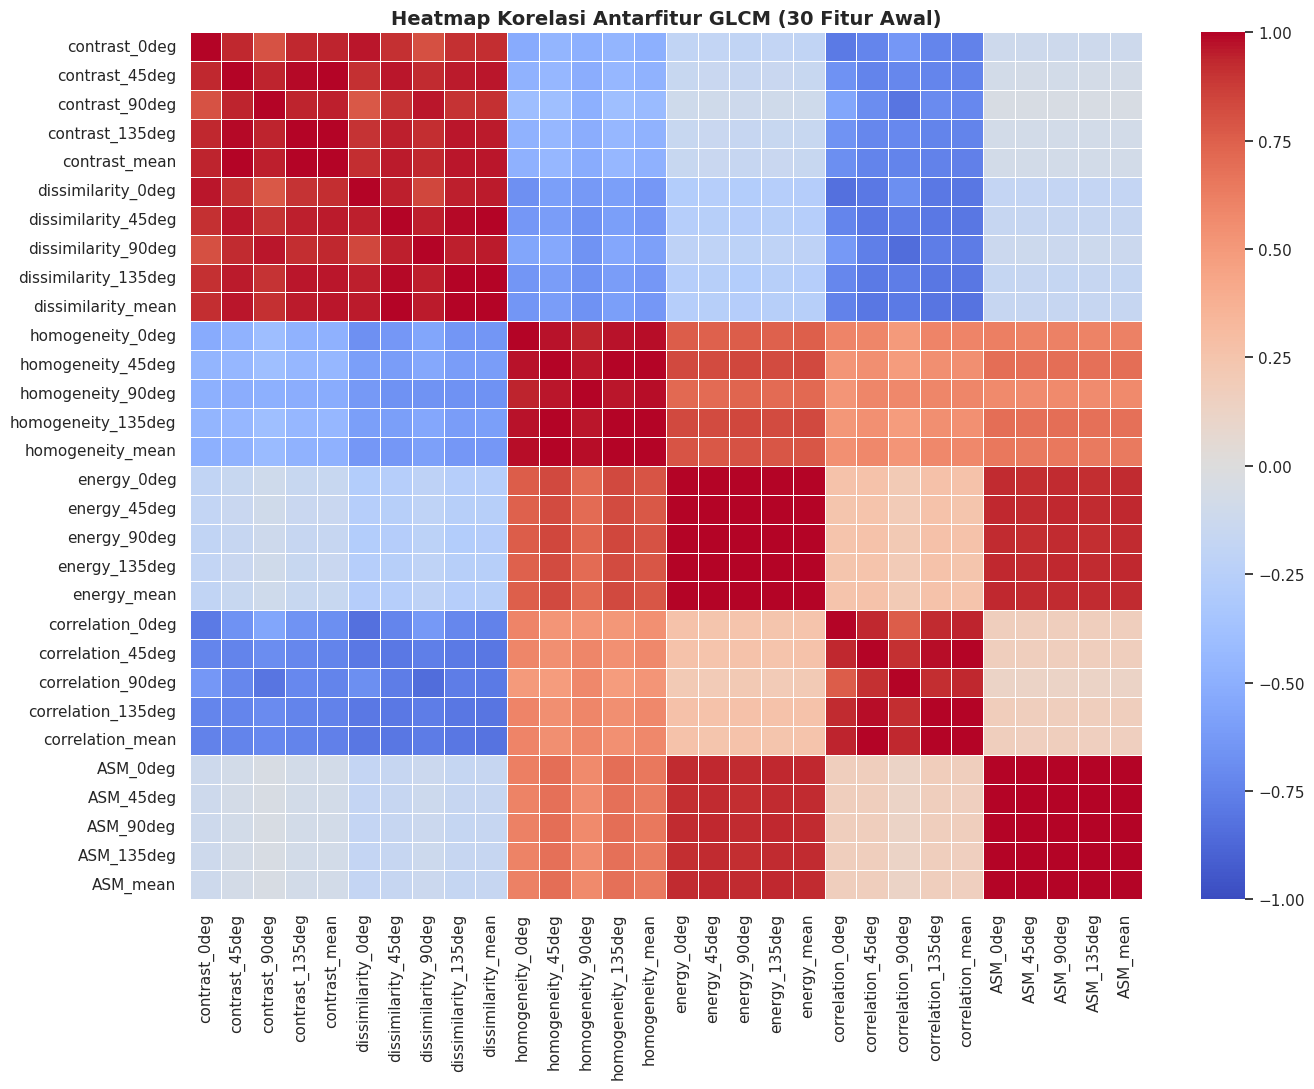

Ditemukan 104 Pasangan Fitur dengan Korelasi Sangat Tinggi (|r| >= 0.90):


,Fitur 1,Fitur 2,Korelasi (r)
0,contrast_0deg,contrast_45deg,0.934651
1,contrast_0deg,contrast_135deg,0.932684
2,contrast_0deg,contrast_mean,0.944519
3,contrast_0deg,dissimilarity_0deg,0.964258
4,contrast_0deg,dissimilarity_45deg,0.911734
5,contrast_0deg,dissimilarity_135deg,0.911262
6,contrast_0deg,dissimilarity_mean,0.920314
7,contrast_45deg,contrast_90deg,0.938654
8,contrast_45deg,contrast_135deg,0.988278
9,contrast_45deg,contrast_mean,0.995178


In [5]:
feature_columns = [c for c in df_features_train.columns if c not in ['Image', 'Class', 'Split']]

X_train_raw = df_features_train[feature_columns].values
y_train = df_features_train['Class'].values

X_val_raw = df_features_val[feature_columns].values
y_val = df_features_val['Class'].values

X_test_raw = df_features_test[feature_columns].values
y_test = df_features_test['Class'].values

# Statistik Deskriptif Fitur GLCM
df_stats = df_features_train[feature_columns].describe().T[['mean', 'std', 'min', '50%', 'max']]
df_stats.columns = ['Mean', 'Std Dev', 'Min', 'Median (Q2)', 'Max']
print("--- Ringkasan Statistik Deskriptif 30 Fitur GLCM (Training Data) ---")
display(df_stats.head(12))

# Matriks Korelasi & Heatmap
plt.figure(figsize=(14, 11))
corr_matrix = df_features_train[feature_columns].corr()
sns.heatmap(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1, annot=False, linewidths=0.5)
plt.title("Heatmap Korelasi Antarfitur GLCM (30 Fitur Awal)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Evaluasi Redundansi Fitur
high_corr_pairs = []
for i in range(len(feature_columns)):
    for j in range(i+1, len(feature_columns)):
        f1, f2 = feature_columns[i], feature_columns[j]
        val = corr_matrix.loc[f1, f2]
        if abs(val) >= 0.90:
            high_corr_pairs.append((f1, f2, val))

df_high_corr = pd.DataFrame(high_corr_pairs, columns=['Fitur 1', 'Fitur 2', 'Korelasi (r)'])
print(f"Ditemukan {len(df_high_corr)} Pasangan Fitur dengan Korelasi Sangat Tinggi (|r| >= 0.90):")
display(df_high_corr.head(10))


### H. Seleksi Fitur Menggunakan SelectKBest (ANOVA F-Test)

#### Urutan Pipeline yang Diverifikasi pada Tahap Ini
`GLCM (30 fitur)` $\rightarrow$ `StandardScaler` $\rightarrow$ `SelectKBest ANOVA F-test (k=15)` $\rightarrow$ `SVM`

#### Rationale Pemilihan Metode
- **Metode Utama**: `SelectKBest` berbasis **ANOVA F-test** (`f_classif`).
- **Alasan Pemilihan**: ANOVA F-test mengukur rasio varians antarkelas terhadap varians dalam-kelas ($F$-score) untuk fitur kontinu (fitur numerik GLCM) terhadap target kategorikal (kelas penyakit). Metode ini efisien, deterministik, dan memiliki landasan statistik yang jelas.
- **Pencegahan Data Leakage**: `selector.fit()` **HANYA** dipanggil pada `X_train_scaled` dan `y_train`. Data `valid/` dan `test/` hanya di-`transform()`.

#### Output yang Ditampilkan
1. Daftar **30 fitur GLCM awal** (24 fitur per sudut + 6 fitur rerata sudut).
2. Tabel ranking seluruh 30 fitur berdasarkan skor ANOVA F.
3. **15 fitur terpilih** (`k=15`) beserta nama fiturnya.


Verifikasi StandardScaler (tanpa data leakage):
  - Jumlah fitur input       : 30
  - Mean hasil fit (3 fitur) : [ 792.6088 1126.4971  784.4354]
  - Skala hasil fit (3 fitur): [626.2677 771.836  634.1903]
  - Shape train (scaled)     : (713, 30)
  - Shape valid (scaled)     : (197, 30)
  - Shape test  (scaled)     : (101, 30)

--- Daftar 30 Fitur GLCM Awal ---


,No,Nama Fitur Awal
0,1,contrast_0deg
1,2,contrast_45deg
2,3,contrast_90deg
3,4,contrast_135deg
4,5,contrast_mean
5,6,dissimilarity_0deg
6,7,dissimilarity_45deg
7,8,dissimilarity_90deg
8,9,dissimilarity_135deg
9,10,dissimilarity_mean



--- Ranking Seluruh 30 Fitur GLCM (ANOVA F-test, fit pada train) ---


,Ranking,Nama Fitur,F-Score,p-value,Status
0,1,dissimilarity_135deg,86.444138,8.463826e-60,Terpilih
1,2,dissimilarity_45deg,85.076584,5.285601e-59,Terpilih
2,3,dissimilarity_mean,81.511598,6.549693e-57,Terpilih
3,4,dissimilarity_90deg,70.365969,3.527857e-50,Terpilih
4,5,dissimilarity_0deg,66.306297,1.183407e-47,Terpilih
5,6,contrast_135deg,63.710240,5.126116e-46,Terpilih
6,7,contrast_45deg,63.262397,9.859593e-46,Terpilih
7,8,contrast_mean,62.078379,5.589481e-45,Terpilih
8,9,correlation_135deg,55.220961,1.526753e-40,Terpilih
9,10,contrast_0deg,53.823972,1.267716e-39,Terpilih


Jumlah fitur awal     : 30
Jumlah fitur terpilih : 15 (k=15)

Daftar 15 Fitur GLCM Terpilih:
   1. contrast_0deg
   2. contrast_45deg
   3. contrast_90deg
   4. contrast_135deg
   5. contrast_mean
   6. dissimilarity_0deg
   7. dissimilarity_45deg
   8. dissimilarity_90deg
   9. dissimilarity_135deg
  10. dissimilarity_mean
  11. homogeneity_90deg
  12. correlation_45deg
  13. correlation_90deg
  14. correlation_135deg
  15. correlation_mean

Shape train (selected): (713, 15)
Shape valid (selected): (197, 15)
Shape test  (selected): (101, 15)


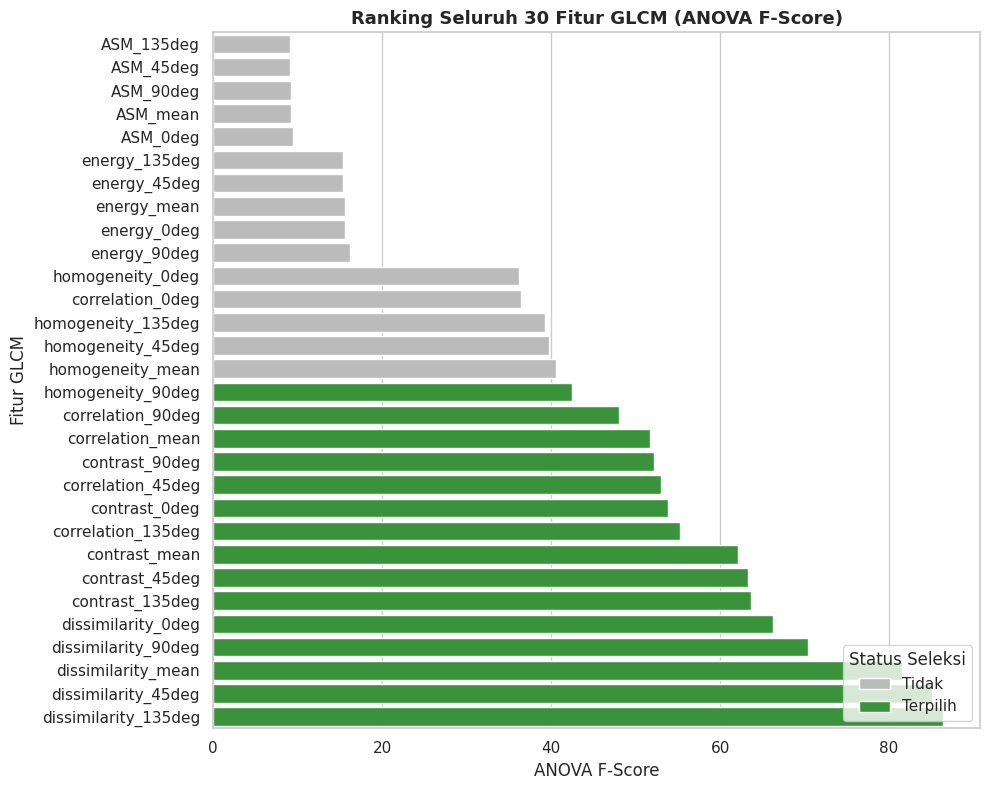

In [6]:
# ============================================================
# LANGKAH 1 - Standardisasi Fitur (StandardScaler)
# FIT HANYA pada training set; valid/ dan test/ hanya transform()
# ============================================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)   # TRAIN : fit + transform
X_val_scaled   = scaler.transform(X_val_raw)         # VALID : transform saja
X_test_scaled  = scaler.transform(X_test_raw)        # TEST  : transform saja

print("Verifikasi StandardScaler (tanpa data leakage):")
print(f"  - Jumlah fitur input       : {X_train_raw.shape[1]}")
print(f"  - Mean hasil fit (3 fitur) : {np.round(scaler.mean_[:3], 4)}")
print(f"  - Skala hasil fit (3 fitur): {np.round(scaler.scale_[:3], 4)}")
print(f"  - Shape train (scaled)     : {X_train_scaled.shape}")
print(f"  - Shape valid (scaled)     : {X_val_scaled.shape}")
print(f"  - Shape test  (scaled)     : {X_test_scaled.shape}")

# ============================================================
# LANGKAH 2 - Daftar 30 Fitur GLCM Awal
# ============================================================
df_initial_features = pd.DataFrame({
    'No': np.arange(1, len(feature_columns) + 1),
    'Nama Fitur Awal': feature_columns
})
print(f"\n--- Daftar {len(feature_columns)} Fitur GLCM Awal ---")
display(df_initial_features)

# ============================================================
# LANGKAH 3 - Seleksi Fitur ANOVA F-test
# FIT HANYA pada X_train_scaled & y_train
# ============================================================
k_best = 15
selector = SelectKBest(score_func=f_classif, k=k_best)
X_train_fs = selector.fit_transform(X_train_scaled, y_train)   # TRAIN : fit + transform
X_val_fs   = selector.transform(X_val_scaled)                  # VALID : transform saja
X_test_fs  = selector.transform(X_test_scaled)                 # TEST  : transform saja

# Tabel ranking seluruh 30 fitur (terpilih / tidak terpilih)
df_ranking_features = pd.DataFrame({
    'Nama Fitur': feature_columns,
    'F-Score': selector.scores_,
    'p-value': selector.pvalues_,
    'Status': ['Terpilih' if s else 'Tidak' for s in selector.get_support()]
}).sort_values(by='F-Score', ascending=False).reset_index(drop=True)
df_ranking_features.insert(0, 'Ranking', np.arange(1, len(df_ranking_features) + 1))

print(f"\n--- Ranking Seluruh {len(feature_columns)} Fitur GLCM (ANOVA F-test, fit pada train) ---")
display(df_ranking_features)

# Daftar 15 fitur terpilih
selected_mask = selector.get_support()
selected_features = [f for f, supp in zip(feature_columns, selected_mask) if supp]

print(f"Jumlah fitur awal     : {len(feature_columns)}")
print(f"Jumlah fitur terpilih : {len(selected_features)} (k={k_best})")
print("\nDaftar 15 Fitur GLCM Terpilih:")
for i, fname in enumerate(selected_features, start=1):
    print(f"  {i:2d}. {fname}")

print(f"\nShape train (selected): {X_train_fs.shape}")
print(f"Shape valid (selected): {X_val_fs.shape}")
print(f"Shape test  (selected): {X_test_fs.shape}")

# Visualisasi ranking F-Score seluruh fitur
df_plot_fs = df_ranking_features.sort_values(by='F-Score', ascending=True)
plt.figure(figsize=(10, 8))
sns.barplot(
    data=df_plot_fs, x='F-Score', y='Nama Fitur',
    hue='Status', dodge=False,
    palette={'Terpilih': '#2ca02c', 'Tidak': '#bbbbbb'}
)
plt.title("Ranking Seluruh 30 Fitur GLCM (ANOVA F-Score)", fontsize=13, fontweight='bold')
plt.xlabel("ANOVA F-Score")
plt.ylabel("Fitur GLCM")
plt.legend(title='Status Seleksi', loc='lower right')
plt.tight_layout()
plt.show()


#### Verifikasi Pipeline dan Integritas Split

Cell berikut melakukan pemeriksaan otomatis bahwa pipeline berjalan sesuai aturan:
- jumlah fitur awal tepat **30** (24 sudut + 6 mean);
- `StandardScaler` dan `SelectKBest` hanya di-`fit` pada data `train/`;
- shape data `valid/` dan `test/` konsisten setelah transformasi;
- tidak ada fitur HSV, bentuk, atau warna pada matriks fitur.


In [7]:
# ============================================================
# VERIFIKASI PIPELINE (GLCM -> Scaling -> ANOVA -> SVM)
# ============================================================
prop_names = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']
expected_angle_features = {f'{p}_{a}deg' for p in prop_names for a in [0, 45, 90, 135]}
expected_mean_features = {f'{p}_mean' for p in prop_names}
expected_all = expected_angle_features | expected_mean_features

actual = set(feature_columns)
assert actual == expected_all, f"Fitur tidak sesuai: {actual ^ expected_all}"
assert len(actual) == 30, f"Jumlah fitur awal {len(actual)} != 30"
assert len(selected_features) == 15, "Jumlah fitur terpilih != 15"
assert X_train_fs.shape[1] == 15
assert X_train_scaled.shape[0] == len(y_train)
assert X_val_scaled.shape[0] == len(y_val)
assert X_test_scaled.shape[0] == len(y_test)

# Cek tidak ada fitur warna/bentuk yang menyusup
forbidden = [c for c in feature_columns if any(k in c.lower() for k in ['hsv', 'hue', 'saturation', 'rgb', 'shape', 'area', 'perimeter'])]
assert not forbidden, f"Fitur terlarang ditemukan: {forbidden}"

print("[OK] Jumlah fitur awal            :", len(actual), "(24 sudut + 6 mean)")
print("[OK] Jumlah fitur terpilih        :", len(selected_features))
print("[OK] Scaler fit hanya pada train  :", scaler.mean_.shape[0] == len(feature_columns))
print("[OK] Selector fit hanya pada train:", selector.scores_.shape[0] == len(feature_columns))
print("[OK] Tidak ada fitur HSV/bentuk/warna pada matriks fitur")
print("[OK] Shape train/valid/test       :", X_train_scaled.shape, X_val_scaled.shape, X_test_scaled.shape)
print("[OK] Pipeline: GLCM(30) -> StandardScaler -> ANOVA(k=15) -> SVM")

# Pemeriksaan tambahan: kelas powdery mildew tidak boleh masuk eksperimen utama
assert set(df_5class['class_name']) == set(target_classes_5), \
    f"Kelas pada dataset eksperimen tidak sesuai 5 kelas target: {set(df_5class['class_name'])}"
assert 'powdery mildew' not in set(df_5class['class_name']), \
    "Kelas 'powdery mildew' masih terdapat pada dataset eksperimen"
print("[OK] Kelas 'powdery mildew' tidak ada pada dataset eksperimen utama (5 kelas)")
print("[OK] Jumlah citra eksperimen :", len(df_5class))


[OK] Jumlah fitur awal            : 30 (24 sudut + 6 mean)
[OK] Jumlah fitur terpilih        : 15
[OK] Scaler fit hanya pada train  : True
[OK] Selector fit hanya pada train: True
[OK] Tidak ada fitur HSV/bentuk/warna pada matriks fitur
[OK] Shape train/valid/test       : (713, 30) (197, 30) (101, 30)
[OK] Pipeline: GLCM(30) -> StandardScaler -> ANOVA(k=15) -> SVM
[OK] Kelas 'powdery mildew' tidak ada pada dataset eksperimen utama (5 kelas)
[OK] Jumlah citra eksperimen : 1011


### I. Pemodelan SVM dan Hyperparameter Tuning

Dua model dibangun dengan tujuan yang berbeda:

1. **Model A — Baseline Internal**: `GLCM (30 fitur) → StandardScaler → SVM`
2. **Model B — Metode Utama Penelitian**: `GLCM (30 fitur) → StandardScaler → SelectKBest ANOVA (15 fitur) → SVM`

#### Aturan Tuning
- `GridSearchCV` **hanya** di-`fit` pada data `train/`.
- Cross-validation: `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.
- Data `valid/` dan `test/` **tidak** digunakan untuk memilih hyperparameter.
- Ruang pencarian:
  - **Kernel**: `rbf`
  - **C**: `[0.1, 1, 10, 100, 500, 1000]`
  - **Gamma**: `['scale', 'auto', 0.001, 0.01, 0.1, 1]`


In [8]:
param_grid = {
    'C': [0.1, 1, 10, 100, 500, 1000],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1],
    'kernel': ['rbf']
}

cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ============================================================
# MODEL A - Baseline Internal : GLCM (30 fitur) -> SVM
# ============================================================
print("Melatih Model A (GLCM -> SVM tanpa seleksi fitur)...")
grid_A = GridSearchCV(
    SVC(random_state=42), param_grid,
    cv=cv_stratified, scoring='accuracy', n_jobs=-1
)
grid_A.fit(X_train_scaled, y_train)   # hanya data train/

best_model_A = grid_A.best_estimator_
y_pred_val_A = best_model_A.predict(X_val_scaled)
y_pred_test_A = best_model_A.predict(X_test_scaled)

# ============================================================
# MODEL B - Metode Utama : GLCM -> ANOVA -> SVM
# ============================================================
print("Melatih Model B (GLCM -> Seleksi Fitur ANOVA -> SVM)...")
grid_B = GridSearchCV(
    SVC(random_state=42), param_grid,
    cv=cv_stratified, scoring='accuracy', n_jobs=-1
)
grid_B.fit(X_train_fs, y_train)       # hanya data train/

best_model_B = grid_B.best_estimator_
y_pred_val_B = best_model_B.predict(X_val_fs)
y_pred_test_B = best_model_B.predict(X_test_fs)

# ============================================================
# RINGKASAN HASIL HYPERPARAMETER TUNING
# ============================================================
print("\n=======================================================")
print("          HASIL HYPERPARAMETER TUNING SVM")
print("=======================================================")

print("Model A (GLCM + SVM, 30 fitur):")
print(f"  - Parameter Terbaik             : {grid_A.best_params_}")
print(f"  - Best CV Score (train, 5-fold) : {grid_A.best_score_*100:.2f}%")
print(f"  - Validation Accuracy (valid/)  : {accuracy_score(y_val, y_pred_val_A)*100:.2f}%")
print(f"  - Test Accuracy (test/)         : {accuracy_score(y_test, y_pred_test_A)*100:.2f}%")

print("\nModel B (GLCM + ANOVA + SVM, 15 fitur):")
print(f"  - Parameter Terbaik             : {grid_B.best_params_}")
print(f"  - Best CV Score (train, 5-fold) : {grid_B.best_score_*100:.2f}%")
print(f"  - Validation Accuracy (valid/)  : {accuracy_score(y_val, y_pred_val_B)*100:.2f}%")
print(f"  - Test Accuracy (test/)         : {accuracy_score(y_test, y_pred_test_B)*100:.2f}%")

# ============================================================
# MODEL FINAL (best_estimator_ hasil GridSearchCV pada train/)
# ============================================================
def summarize_final_model(nama_model, grid_model, jumlah_fitur):
    est = grid_model.best_estimator_
    print(f"\n[{nama_model}] MODEL FINAL")
    print(f"  - Kernel               : {est.kernel}")
    print(f"  - C                    : {est.C}")
    print(f"  - Gamma                : {est.gamma}")
    print(f"  - Jumlah fitur input   : {jumlah_fitur}")
    print(f"  - Jumlah support vector: {int(est.n_support_.sum())}")
    print(f"  - Kelas                : {list(est.classes_)}")
    print(f"  - Best CV score (train): {grid_model.best_score_*100:.2f}%")
    return est

final_model_A = summarize_final_model("Model A - Baseline", grid_A, X_train_scaled.shape[1])
final_model_B = summarize_final_model("Model B - Utama", grid_B, X_train_fs.shape[1])

# Tabel perbandingan konfigurasi model
df_model_config = pd.DataFrame([
    {
        'Model': 'Model A (Baseline)',
        'Pipeline': 'GLCM -> StandardScaler -> SVM',
        'Jumlah Fitur': X_train_scaled.shape[1],
        'Kernel': final_model_A.kernel,
        'C': final_model_A.C,
        'Gamma': final_model_A.gamma,
        'Best CV Score (Train)': f"{grid_A.best_score_*100:.2f}%"
    },
    {
        'Model': 'Model B (Utama)',
        'Pipeline': 'GLCM -> StandardScaler -> ANOVA(k=15) -> SVM',
        'Jumlah Fitur': X_train_fs.shape[1],
        'Kernel': final_model_B.kernel,
        'C': final_model_B.C,
        'Gamma': final_model_B.gamma,
        'Best CV Score (Train)': f"{grid_B.best_score_*100:.2f}%"
    }
])

print("\n--- Ringkasan Konfigurasi Model Final ---")
display(df_model_config)


Melatih Model A (GLCM -> SVM tanpa seleksi fitur)...


Melatih Model B (GLCM -> Seleksi Fitur ANOVA -> SVM)...



          HASIL HYPERPARAMETER TUNING SVM
Model A (GLCM + SVM, 30 fitur):
  - Parameter Terbaik             : {'C': 1000, 'gamma': 0.1, 'kernel': 'rbf'}
  - Best CV Score (train, 5-fold) : 55.69%
  - Validation Accuracy (valid/)  : 58.38%
  - Test Accuracy (test/)         : 55.45%

Model B (GLCM + ANOVA + SVM, 15 fitur):
  - Parameter Terbaik             : {'C': 1000, 'gamma': 0.1, 'kernel': 'rbf'}
  - Best CV Score (train, 5-fold) : 54.70%
  - Validation Accuracy (valid/)  : 47.72%
  - Test Accuracy (test/)         : 54.46%

[Model A - Baseline] MODEL FINAL
  - Kernel               : rbf
  - C                    : 1000
  - Gamma                : 0.1
  - Jumlah fitur input   : 30
  - Jumlah support vector: 556
  - Kelas                : ['healthy', 'leaf curl', 'leaf spot', 'whitefly', 'yellowish']
  - Best CV score (train): 55.69%

[Model B - Utama] MODEL FINAL
  - Kernel               : rbf
  - C                    : 1000
  - Gamma                : 0.1
  - Jumlah fitur input   : 15


,Model,Pipeline,Jumlah Fitur,Kernel,C,Gamma,Best CV Score (Train)
0,Model A (Baseline),GLCM -> StandardScaler -> SVM,30,rbf,1000,0.1,55.69%
1,Model B (Utama),GLCM -> StandardScaler -> ANOVA(k=15) -> SVM,15,rbf,1000,0.1,54.70%


### J. Classification Report dan Evaluasi Performa per Kelas

Evaluasi dilakukan **hanya pada data uji (`test/`)** yang tidak pernah digunakan pada proses pelatihan, standardisasi, seleksi fitur, maupun tuning hyperparameter.

#### Metrik dan Metode Averaging
- **Accuracy**: proporsi prediksi benar terhadap seluruh sampel uji.
- **Precision, Recall, F1-score per kelas**: dihitung untuk masing-masing kelas.
- **Macro average**: rata-rata sederhana antar kelas (setiap kelas berbobot sama, tanpa mempertimbangkan jumlah sampel).
- **Weighted average**: rata-rata yang dibobotkan berdasarkan jumlah sampel (*support*) tiap kelas.

Kedua jenis averaging dilaporkan agar tidak menimbulkan ambiguitas pembacaan. Pada tabel ringkasan (Section L), nilai yang ditampilkan adalah **weighted average**, dan tabel macro average ditampilkan terpisah.


In [9]:
report_A_str = classification_report(
    y_test, y_pred_test_A, digits=4, target_names=sorted(target_classes_5)
)
report_B_str = classification_report(
    y_test, y_pred_test_B, digits=4, target_names=sorted(target_classes_5)
)

print("==========================================================")
print("     CLASSIFICATION REPORT - MODEL A (GLCM + SVM - TEST SET)")
print("==========================================================")
print(report_A_str)

print("\n==========================================================")
print(" CLASSIFICATION REPORT - MODEL B (GLCM + FS + SVM - TEST SET)")
print("==========================================================")
print(report_B_str)

# ------------------------------------------------------------
# Ringkasan macro vs weighted average (dihitung dari prediksi)
# ------------------------------------------------------------
def ringkasan_averaging(y_true, y_pred, nama_model):
    rows = []
    for avg_name in ['macro', 'weighted']:
        p, r, f, _ = precision_recall_fscore_support(
            y_true, y_pred, average=avg_name, zero_division=0
        )
        rows.append({
            'Model': nama_model,
            'Averaging': avg_name,
            'Precision': round(p * 100, 2),
            'Recall': round(r * 100, 2),
            'F1-Score': round(f * 100, 2),
        })
    return rows

df_avg = pd.DataFrame(
    ringkasan_averaging(y_test, y_pred_test_A, 'GLCM + SVM (Model A)')
    + ringkasan_averaging(y_test, y_pred_test_B, 'GLCM + FS + SVM (Model B)')
)
print("\n--- Ringkasan Metrik Berdasarkan Metode Averaging (Test Set) ---")
print("Catatan: nilai dalam persen (%). Macro = rata-rata antar kelas; Weighted = dibobotkan support.")
display(df_avg)


     CLASSIFICATION REPORT - MODEL A (GLCM + SVM - TEST SET)
              precision    recall  f1-score   support

     healthy     0.5000    0.5714    0.5333        21
   leaf curl     0.4783    0.4783    0.4783        23
   leaf spot     0.5172    0.7500    0.6122        20
    whitefly     0.6250    0.2500    0.3571        20
   yellowish     0.7647    0.7647    0.7647        17

    accuracy                         0.5545       101
   macro avg     0.5770    0.5629    0.5491       101
weighted avg     0.5678    0.5545    0.5405       101


 CLASSIFICATION REPORT - MODEL B (GLCM + FS + SVM - TEST SET)
              precision    recall  f1-score   support

     healthy     0.5556    0.4762    0.5128        21
   leaf curl     0.5455    0.5217    0.5333        23
   leaf spot     0.4848    0.8000    0.6038        20
    whitefly     0.6667    0.3000    0.4138        20
   yellowish     0.5789    0.6471    0.6111        17

    accuracy                         0.5446       101
   macr

,Model,Averaging,Precision,Recall,F1-Score
0,GLCM + SVM (Model A),macro,57.70,56.29,54.91
1,GLCM + SVM (Model A),weighted,56.78,55.45,54.05
2,GLCM + FS + SVM (Model B),macro,56.63,54.90,53.50
3,GLCM + FS + SVM (Model B),weighted,56.52,54.46,53.24


### K. Analisis Confusion Matrix

Confusion matrix menampilkan distribusi prediksi untuk setiap kelas aktual pada data uji (`test/`).

#### Cara Membaca
- **Diagonal utama**: jumlah prediksi benar untuk setiap kelas.
- **Sel di luar diagonal**: kesalahan klasifikasi (kelas aktual $i$ diprediksi sebagai kelas $j$).
- **Recall per kelas** dihitung sebagai $\frac{\text{jumlah prediksi benar kelas } i}{\text{jumlah sampel aktual kelas } i}$, sehingga dapat digunakan untuk mengidentifikasi kelas yang relatif mudah atau sulit dikenali oleh model.

Analisis di bawah ini bersifat **interpretatif** dan dibatasi pada pola yang terlihat pada confusion matrix serta karakteristik fitur tekstur keabuan GLCM. Analisis ini bukan klaim kausal mengenai penyebab biologis kesalahan klasifikasi.


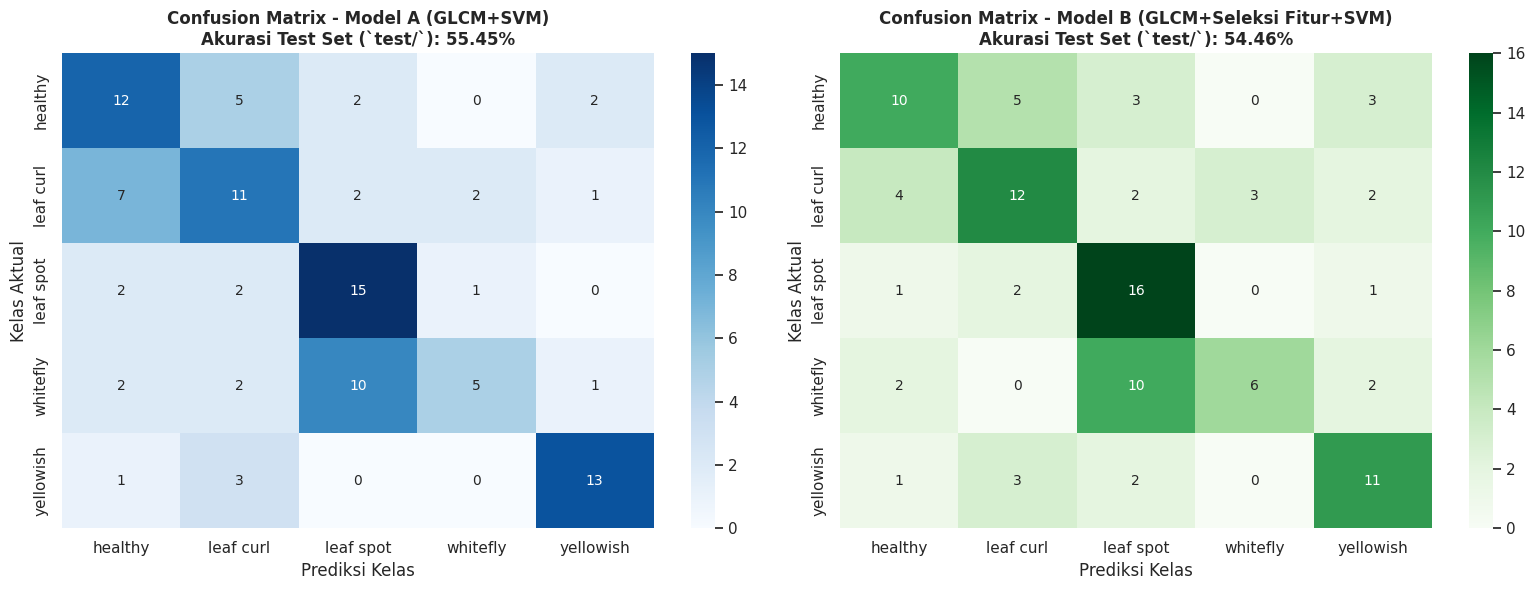


ANALISIS CONFUSION MATRIX - MODEL A (GLCM + SVM)

Recall per kelas (diurutkan dari tertinggi):


,Kelas,Support (aktual),Prediksi Benar,Recall (%)
0,yellowish,17,13,76.47
1,leaf spot,20,15,75.00
2,healthy,21,12,57.14
3,leaf curl,23,11,47.83
4,whitefly,20,5,25.00


Kelas dengan recall tertinggi (paling banyak dikenali benar): 'yellowish' (76.47%, 13/17 sampel).
Kelas dengan recall terendah (paling sering salah dikenali): 'whitefly' (25.00%, 5/20 sampel).

3 pasangan kesalahan klasifikasi terbanyak:


,Kelas Aktual,Diprediksi Sebagai,Jumlah
0,whitefly,leaf spot,10
1,leaf curl,healthy,7
2,healthy,leaf curl,5


Pasangan kesalahan terbanyak: 'whitefly' diprediksi sebagai 'leaf spot' sebanyak 10 kali.

ANALISIS CONFUSION MATRIX - MODEL B (GLCM + FS + SVM)

Recall per kelas (diurutkan dari tertinggi):


,Kelas,Support (aktual),Prediksi Benar,Recall (%)
0,leaf spot,20,16,80.00
1,yellowish,17,11,64.71
2,leaf curl,23,12,52.17
3,healthy,21,10,47.62
4,whitefly,20,6,30.00


Kelas dengan recall tertinggi (paling banyak dikenali benar): 'leaf spot' (80.00%, 16/20 sampel).
Kelas dengan recall terendah (paling sering salah dikenali): 'whitefly' (30.00%, 6/20 sampel).

3 pasangan kesalahan klasifikasi terbanyak:


,Kelas Aktual,Diprediksi Sebagai,Jumlah
0,whitefly,leaf spot,10
1,healthy,leaf curl,5
2,leaf curl,healthy,4


Pasangan kesalahan terbanyak: 'whitefly' diprediksi sebagai 'leaf spot' sebanyak 10 kali.


In [10]:
class_labels = sorted(target_classes_5)

cm_A = confusion_matrix(y_test, y_pred_test_A, labels=class_labels)
cm_B = confusion_matrix(y_test, y_pred_test_B, labels=class_labels)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(cm_A, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels, ax=axes[0])
axes[0].set_title(
    f"Confusion Matrix - Model A (GLCM+SVM)\nAkurasi Test Set (`test/`): {accuracy_score(y_test, y_pred_test_A)*100:.2f}%",
    fontsize=12, fontweight='bold'
)
axes[0].set_xlabel("Prediksi Kelas")
axes[0].set_ylabel("Kelas Aktual")

sns.heatmap(cm_B, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_labels, yticklabels=class_labels, ax=axes[1])
axes[1].set_title(
    f"Confusion Matrix - Model B (GLCM+Seleksi Fitur+SVM)\nAkurasi Test Set (`test/`): {accuracy_score(y_test, y_pred_test_B)*100:.2f}%",
    fontsize=12, fontweight='bold'
)
axes[1].set_xlabel("Prediksi Kelas")
axes[1].set_ylabel("Kelas Aktual")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Analisis kuantitatif confusion matrix (dihitung dari matriks)
# ------------------------------------------------------------
def analisis_confusion_matrix(cm, labels, nama_model, top_n=3):
    cm = np.asarray(cm)
    support = cm.sum(axis=1)
    benar = np.diag(cm)
    recall = np.divide(benar, support, out=np.zeros_like(benar, dtype=float), where=support > 0)

    df_recall = pd.DataFrame({
        'Kelas': labels,
        'Support (aktual)': support,
        'Prediksi Benar': benar,
        'Recall (%)': np.round(recall * 100, 2)
    }).sort_values('Recall (%)', ascending=False).reset_index(drop=True)

    # pasangan tertukar (off-diagonal)
    pairs = []
    for i in range(len(labels)):
        for j in range(len(labels)):
            if i != j and cm[i, j] > 0:
                pairs.append({
                    'Kelas Aktual': labels[i],
                    'Diprediksi Sebagai': labels[j],
                    'Jumlah': int(cm[i, j])
                })
    df_pairs = pd.DataFrame(pairs).sort_values('Jumlah', ascending=False).reset_index(drop=True)

    print(f"\n{'='*70}")
    print(f"ANALISIS CONFUSION MATRIX - {nama_model}")
    print(f"{'='*70}")
    print("\nRecall per kelas (diurutkan dari tertinggi):")
    display(df_recall)

    termudah = df_recall.iloc[0]
    tersulit = df_recall.iloc[-1]
    print(f"Kelas dengan recall tertinggi (paling banyak dikenali benar): "
          f"'{termudah['Kelas']}' ({termudah['Recall (%)']:.2f}%, {termudah['Prediksi Benar']}/{termudah['Support (aktual)']} sampel).")
    print(f"Kelas dengan recall terendah (paling sering salah dikenali): "
          f"'{tersulit['Kelas']}' ({tersulit['Recall (%)']:.2f}%, {tersulit['Prediksi Benar']}/{tersulit['Support (aktual)']} sampel).")

    if len(df_pairs) > 0:
        print(f"\n{top_n} pasangan kesalahan klasifikasi terbanyak:")
        display(df_pairs.head(top_n))
        teratas = df_pairs.iloc[0]
        print(f"Pasangan kesalahan terbanyak: '{teratas['Kelas Aktual']}' diprediksi sebagai "
              f"'{teratas['Diprediksi Sebagai']}' sebanyak {teratas['Jumlah']} kali.")
    else:
        print("\nTidak terdapat kesalahan klasifikasi (seluruh sampel uji terprediksi benar).")

    return df_recall, df_pairs, termudah['Kelas'], tersulit['Kelas']


recall_A, pairs_A, mudah_A, sulit_A = analisis_confusion_matrix(cm_A, class_labels, "MODEL A (GLCM + SVM)")
recall_B, pairs_B, mudah_B, sulit_B = analisis_confusion_matrix(cm_B, class_labels, "MODEL B (GLCM + FS + SVM)")


In [11]:
# ============================================================
# NARASI INTERPRETASI CONFUSION MATRIX
# Seluruh angka diambil dari hasil perhitungan di atas (tidak ditulis manual)
# ============================================================
def narasi_confusion(nama_model, df_recall, df_pairs, kelas_mudah, kelas_sulit, n_test):
    print(f"\n{'-'*70}")
    print(f"INTERPRETASI RINGKAS - {nama_model}")
    print(f"{'-'*70}")

    baris_mudah = df_recall[df_recall['Kelas'] == kelas_mudah].iloc[0]
    baris_sulit = df_recall[df_recall['Kelas'] == kelas_sulit].iloc[0]

    print(f"1) Kelas yang paling mudah dikenali model pada test set ini: '{kelas_mudah}' "
          f"(recall {baris_mudah['Recall (%)']:.2f}%, "
          f"{baris_mudah['Prediksi Benar']}/{baris_mudah['Support (aktual)']} sampel benar).")
    print(f"2) Kelas yang paling sering salah dikenali: '{kelas_sulit}' "
          f"(recall {baris_sulit['Recall (%)']:.2f}%, "
          f"{baris_sulit['Prediksi Benar']}/{baris_sulit['Support (aktual)']} sampel benar).")

    if len(df_pairs) > 0:
        t = df_pairs.iloc[0]
        print(f"3) Pasangan paling sering tertukar: '{t['Kelas Aktual']}' diprediksi sebagai "
              f"'{t['Diprediksi Sebagai']}' sebanyak {t['Jumlah']} kali "
              f"({t['Jumlah']/n_test*100:.2f}% dari {n_test} citra uji).")
    else:
        print("3) Tidak terdapat kesalahan klasifikasi pada test set ini.")

    print("   Catatan: identifikasi di atas murni hasil hitung confusion matrix, "
          "bukan penilaian subjektif terhadap kemiripan visual citra.")


narasi_confusion("MODEL A (GLCM + SVM)", recall_A, pairs_A, mudah_A, sulit_A, len(y_test))
narasi_confusion("MODEL B (GLCM + FS + SVM)", recall_B, pairs_B, mudah_B, sulit_B, len(y_test))



----------------------------------------------------------------------
INTERPRETASI RINGKAS - MODEL A (GLCM + SVM)
----------------------------------------------------------------------
1) Kelas yang paling mudah dikenali model pada test set ini: 'yellowish' (recall 76.47%, 13/17 sampel benar).
2) Kelas yang paling sering salah dikenali: 'whitefly' (recall 25.00%, 5/20 sampel benar).
3) Pasangan paling sering tertukar: 'whitefly' diprediksi sebagai 'leaf spot' sebanyak 10 kali (9.90% dari 101 citra uji).
   Catatan: identifikasi di atas murni hasil hitung confusion matrix, bukan penilaian subjektif terhadap kemiripan visual citra.

----------------------------------------------------------------------
INTERPRETASI RINGKAS - MODEL B (GLCM + FS + SVM)
----------------------------------------------------------------------
1) Kelas yang paling mudah dikenali model pada test set ini: 'leaf spot' (recall 80.00%, 16/20 sampel benar).
2) Kelas yang paling sering salah dikenali: 'whitefly' (re

#### Interpretasi Berbasis Karakteristik Tekstur (Hipotesis, Bukan Fakta Mutlak)

Pola pada confusion matrix di atas dapat dibaca dengan menghubungkannya ke sifat fitur GLCM pada citra keabuan. Penjelasan berikut adalah **interpretasi** yang konsisten dengan pola tersebut, bukan bukti kausal:

- **Kelas yang relatif mudah dikenali** umumnya memiliki pola tekstur keabuan yang lebih khas, sehingga nilai kontras, *dissimilarity*, dan korelasi antar piksel bertetangga lebih mudah dipisahkan oleh bidang pemisah SVM. Jika kelas tersebut justru berkaitan erat dengan perubahan warna, hasil ini perlu dibaca hati-hati karena warna tidak direpresentasikan pada citra keabuan.
- **Kelas dengan recall rendah** memiliki fitur tekstur yang tumpang tindih dengan kelas lain, sehingga vektor fiturnya berdekatan di ruang 30 dimensi (Model A) maupun 15 dimensi (Model B).
- **Pasangan kelas yang paling sering tertukar** menunjukkan bahwa kedua kelas menghasilkan statistik ko-okurensi yang berdekatan. GLCM pada `distance=1` dengan empat arah hanya merangkum hubungan piksel bertetangga terdekat, sehingga pola bercak kecil dengan ukuran dan kerapatan mirip dapat menghasilkan nilai kontras dan *dissimilarity* yang serupa. Interpretasi ini menjelaskan **mengapa secara tekstur** kedua kelas sulit dipisahkan, bukan mengklaim penyebab biologisnya.
- Perbedaan susunan kesalahan antara Model A dan Model B menunjukkan bahwa pemilihan 15 fitur mengubah informasi tekstur yang tersedia bagi SVM, sehingga kelas yang paling mudah/sulit dikenali dapat bergeser antar model.

Untuk memastikan penyebab kesalahan, diperlukan pemeriksaan visual per citra yang salah diklasifikasi serta pengujian fitur tambahan. Hal itu berada di luar cakupan eksperimen ini.


### L. Tabel Perbandingan Model A vs Model B (Test Set)

Tabel berikut merangkum metrik evaluasi kedua model pada data uji internal (`test/`). Seluruh nilai dihitung langsung dari prediksi model pada notebook ini (**tidak ditulis manual**).

#### Definisi Kolom
- **Accuracy**: proporsi prediksi benar terhadap seluruh sampel uji.
- **Precision / Recall / F1-score**: menggunakan **weighted average**, yaitu rata-rata yang dibobotkan berdasarkan jumlah sampel (*support*) tiap kelas.
- Tabel pendamping dengan **macro average** disajikan setelah tabel utama, karena macro average memberi bobot sama untuk setiap kelas.

Perbandingan dengan angka MobileNet dari jurnal acuan **tidak** diletakkan pada tabel ini; perbandingan tersebut dibahas terpisah pada Section N agar hasil internal dan hasil rujukan tidak tercampur.


  TABEL PERBANDINGAN MODEL A vs MODEL B (TEST SET, WEIGHTED AVERAGE)


,Model,Accuracy,Precision,Recall,F1-score
0,GLCM + SVM,55.45%,56.78%,55.45%,54.05%
1,GLCM + Feature Selection + SVM,54.46%,56.52%,54.46%,53.24%


Catatan: Precision/Recall/F1-score pada tabel di atas menggunakan weighted average.

  TABEL PENDAMPING: METRIK MACRO AVERAGE (TEST SET)


,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,GLCM + SVM,55.45%,57.70%,56.29%,54.91%
1,GLCM + Feature Selection + SVM,54.46%,56.63%,54.90%,53.50%



--- Selisih Performa Model B terhadap Model A (Test Set, weighted) ---
  Delta Accuracy : -0.99 poin persentase
  Delta F1-score : -0.80 poin persentase
  Interpretasi   : perbedaan accuracy kurang dari 1 poin persentase (relatif kecil pada test set ini).


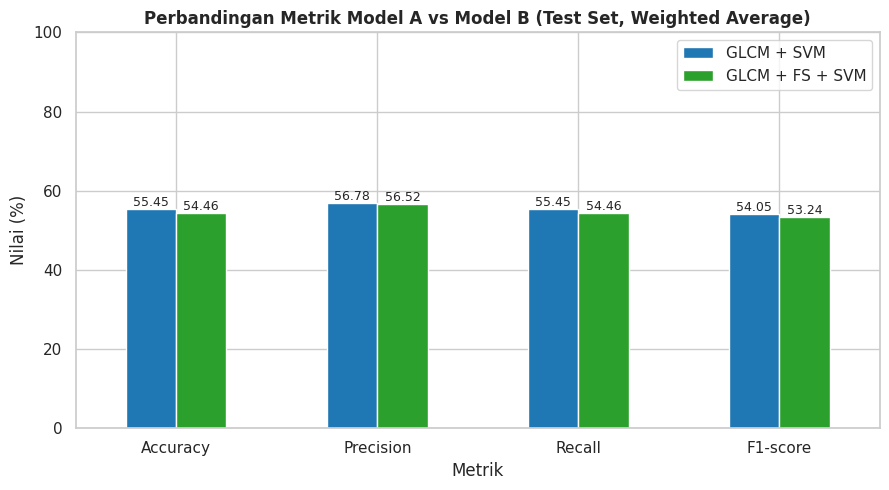

In [12]:
# ============================================================
# Metrik evaluasi pada test set (dihitung dari prediksi aktual)
# ============================================================
def hitung_metrik(y_true, y_pred, average):
    acc = accuracy_score(y_true, y_pred)
    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, average=average, zero_division=0
    )
    return acc, p, r, f


acc_A, p_w_A, r_w_A, f_w_A = hitung_metrik(y_test, y_pred_test_A, 'weighted')
acc_B, p_w_B, r_w_B, f_w_B = hitung_metrik(y_test, y_pred_test_B, 'weighted')

# ------------------------------------------------------------
# Tabel utama (weighted average)
# ------------------------------------------------------------
df_comparison = pd.DataFrame([
    {
        'Model': 'GLCM + SVM',
        'Accuracy': f"{acc_A*100:.2f}%",
        'Precision': f"{p_w_A*100:.2f}%",
        'Recall': f"{r_w_A*100:.2f}%",
        'F1-score': f"{f_w_A*100:.2f}%"
    },
    {
        'Model': 'GLCM + Feature Selection + SVM',
        'Accuracy': f"{acc_B*100:.2f}%",
        'Precision': f"{p_w_B*100:.2f}%",
        'Recall': f"{r_w_B*100:.2f}%",
        'F1-score': f"{f_w_B*100:.2f}%"
    }
])

print("==============================================================================")
print("  TABEL PERBANDINGAN MODEL A vs MODEL B (TEST SET, WEIGHTED AVERAGE)")
print("==============================================================================")
display(df_comparison)
print("Catatan: Precision/Recall/F1-score pada tabel di atas menggunakan weighted average.")

# ------------------------------------------------------------
# Tabel pendamping (macro average)
# ------------------------------------------------------------
acc_mA, p_mA, r_mA, f_mA = hitung_metrik(y_test, y_pred_test_A, 'macro')
acc_mB, p_mB, r_mB, f_mB = hitung_metrik(y_test, y_pred_test_B, 'macro')

df_comparison_macro = pd.DataFrame([
    {
        'Model': 'GLCM + SVM',
        'Accuracy': f"{acc_A*100:.2f}%",
        'Precision (macro)': f"{p_mA*100:.2f}%",
        'Recall (macro)': f"{r_mA*100:.2f}%",
        'F1-score (macro)': f"{f_mA*100:.2f}%"
    },
    {
        'Model': 'GLCM + Feature Selection + SVM',
        'Accuracy': f"{acc_B*100:.2f}%",
        'Precision (macro)': f"{p_mB*100:.2f}%",
        'Recall (macro)': f"{r_mB*100:.2f}%",
        'F1-score (macro)': f"{f_mB*100:.2f}%"
    }
])

print("\n==============================================================================")
print("  TABEL PENDAMPING: METRIK MACRO AVERAGE (TEST SET)")
print("==============================================================================")
display(df_comparison_macro)

# ------------------------------------------------------------
# Selisih performa Model B terhadap Model A (dihitung otomatis)
# ------------------------------------------------------------
delta_acc = (acc_B - acc_A) * 100
delta_f1 = (f_w_B - f_w_A) * 100

print("\n--- Selisih Performa Model B terhadap Model A (Test Set, weighted) ---")
print(f"  Delta Accuracy : {delta_acc:+.2f} poin persentase")
print(f"  Delta F1-score : {delta_f1:+.2f} poin persentase")
if abs(delta_acc) < 1.0:
    print("  Interpretasi   : perbedaan accuracy kurang dari 1 poin persentase (relatif kecil pada test set ini).")
else:
    arah = "meningkat" if delta_acc > 0 else "menurun"
    print(f"  Interpretasi   : accuracy Model B {arah} {abs(delta_acc):.2f} poin persentase pada test set ini.")

# ------------------------------------------------------------
# Visualisasi ringkas perbandingan Model A vs Model B
# ------------------------------------------------------------
df_plot = pd.DataFrame({
    'Metrik': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'GLCM + SVM': [acc_A*100, p_w_A*100, r_w_A*100, f_w_A*100],
    'GLCM + FS + SVM': [acc_B*100, p_w_B*100, r_w_B*100, f_w_B*100]
}).set_index('Metrik')

ax = df_plot.plot(kind='bar', figsize=(9, 5), color=['#1f77b4', '#2ca02c'], rot=0)
ax.set_ylim(0, 100)
ax.set_ylabel("Nilai (%)")
ax.set_title("Perbandingan Metrik Model A vs Model B (Test Set, Weighted Average)", fontweight='bold')
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', fontsize=9)
plt.tight_layout()
plt.show()


### M. External Testing / Pengujian Eksternal (Opsional)

Bagian ini bersifat **opsional** dan hanya dijalankan apabila tersedia citra di luar dataset penelitian. Tujuannya menguji sejauh mana model final yang sudah dilatih bekerja pada citra baru, bukan untuk memperbaiki model.

#### Aturan Isolasi Data
Citra eksternal **tidak boleh** dicampurkan ke dalam:
- data `train/` (pelatihan),
- data `valid/` (pemantauan),
- data `test/` (evaluasi internal),
- proses `SelectKBest` (pemilihan fitur),
- proses `GridSearchCV` (tuning hyperparameter).

Citra eksternal hanya digunakan **setelah model final selesai dilatih**. `StandardScaler` dan `SelectKBest` **tidak di-fit ulang**, hyperparameter **tidak di-tuning ulang**, dan hasil pengujian eksternal **tidak digunakan untuk mengubah model** dalam bentuk apa pun.

#### Struktur Folder yang Diharapkan
```
external_test/
├── healthy/
├── leaf curl/
├── leaf spot/
├── whitefly/
└── yellowish/
```
Nama subfolder harus sama dengan nama kelas (huruf kecil). Format citra yang didukung: `.jpg`, `.jpeg`, `.png`, `.bmp`, `.tif`, `.tiff`.

#### Alur Pemrosesan (Identik dengan Pelatihan)
`Citra eksternal` $\rightarrow$ `Resize 128x128` $\rightarrow$ `Grayscale` $\rightarrow$ `GLCM (30 fitur)` $\rightarrow$ `scaler.transform()` $\rightarrow$ `selector.transform()` $\rightarrow$ `SVM model final`

Urutan `scaler.transform()` lalu `selector.transform()` mengikuti urutan pipeline saat pelatihan (scaler di-fit lebih dahulu, selector di-fit pada data yang sudah terstandardisasi). Keduanya dipanggil dalam mode **transform saja**.

#### Perilaku Notebook
- **Jika folder `external_test/` belum tersedia**: bagian ini mencetak status "belum tersedia", melewati proses, dan notebook tetap berjalan tanpa error. Tidak ada data yang dibuat atau disimulasikan.
- **Jika folder tersedia dan berisi citra berlabel**: ditampilkan accuracy, precision, recall, F1-score (weighted dan macro), classification report, serta confusion matrix untuk kedua model.
- **Jika folder tersedia tetapi tidak berisi subfolder kelas**: hanya ditampilkan daftar prediksi tanpa metrik.

Hasil pengujian eksternal selalu ditampilkan **terpisah** dari hasil test internal (`test/`).


In [13]:
# ============================================================
# M. EXTERNAL TESTING (OPSIONAL)
# Aturan: tidak ada fit ulang scaler/selector, tidak ada tuning ulang,
# dan hasilnya tidak dipakai untuk mengubah model.
# ============================================================
from pathlib import Path

EXTERNAL_DIR = Path('external_test')
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}
class_labels_ext = sorted(target_classes_5)

external_available = EXTERNAL_DIR.is_dir()

print("=" * 78)
print("  PENGUJIAN EKSTERNAL (EXTERNAL TESTING) - OPSIONAL")
print("=" * 78)
print(f"Lokasi yang diperiksa : {EXTERNAL_DIR.resolve()}")

if not external_available:
    print("\n[STATUS] Folder 'external_test/' BELUM TERSEDIA.")
    print("         Bagian pengujian eksternal DILEWATI; notebook tetap berjalan tanpa error.")
    print("         Tidak ada citra eksternal yang dibuat, disalin, atau disimulasikan.")
    print("\nStruktur folder yang diharapkan:")
    print("  external_test/")
    for cls in class_labels_ext:
        print(f"    {cls}/")
    print("\nHasil pengujian eksternal (bila nanti dijalankan) TIDAK digunakan untuk mengubah model.")
else:
    # --------------------------------------------------------
    # 1. Kumpulkan citra eksternal (label diambil dari nama subfolder)
    # --------------------------------------------------------
    records = []
    for cls in class_labels_ext:
        cls_dir = EXTERNAL_DIR / cls
        if not cls_dir.is_dir():
            continue
        for p in sorted(cls_dir.rglob('*')):
            if p.is_file() and p.suffix.lower() in IMG_EXTS:
                records.append({
                    'filepath': str(p),
                    'filename': p.name,
                    'class_name': cls,
                    'split': 'external'
                })

    df_external = pd.DataFrame(records)
    print(f"\nJumlah citra eksternal berlabel yang ditemukan : {len(df_external)}")

    if len(df_external) == 0:
        print("\n[STATUS] Folder 'external_test/' tersedia, tetapi tidak ada citra berlabel "
              "pada subfolder kelas.")
        print("         Bagian ini dilewati tanpa error.")
    else:
        # --------------------------------------------------------
        # 2. Pastikan tidak ada tumpang tindih berkas dengan dataset internal
        # --------------------------------------------------------
        internal_paths = {str(Path(p).resolve()).lower() for p in df_5class['filepath']}
        external_paths = {str(Path(p).resolve()).lower() for p in df_external['filepath']}
        overlap = internal_paths & external_paths
        assert not overlap, f"Citra eksternal tumpang tindih dengan dataset internal: {list(overlap)[:3]}"
        print("[OK] Tidak ada berkas eksternal yang juga berada di dataset internal (train/valid/test).")

        # --------------------------------------------------------
        # 3. Ekstraksi GLCM dengan parameter identik (tanpa augmentasi)
        # --------------------------------------------------------
        print("\nEkstraksi fitur GLCM pada citra eksternal (parameter identik dengan pelatihan)...")
        t_ext = time.time()
        df_ext_features = extract_glcm_features_from_df(df_external)
        print(f"Selesai dalam {time.time() - t_ext:.2f} detik | shape matriks: {df_ext_features.shape}")

        assert set(feature_columns).issubset(set(df_ext_features.columns)), \
            "Kolom fitur eksternal tidak lengkap dibanding fitur pelatihan"

        X_ext_raw = df_ext_features[feature_columns].values
        y_ext = df_ext_features['Class'].values

        # --------------------------------------------------------
        # 4. Transformasi memakai objek yang SUDAH di-fit pada train/
        #    (TANPA fit ulang; urutan mengikuti pipeline pelatihan)
        # --------------------------------------------------------
        X_ext_scaled = scaler.transform(X_ext_raw)     # transform saja
        X_ext_fs = selector.transform(X_ext_scaled)    # transform saja

        assert X_ext_scaled.shape[1] == X_train_scaled.shape[1], "Dimensi scaled eksternal tidak sesuai"
        assert X_ext_fs.shape[1] == X_train_fs.shape[1], "Dimensi fitur terpilih eksternal tidak sesuai"

        print("[OK] scaler.transform() dipakai tanpa fit ulang")
        print("[OK] selector.transform() dipakai tanpa fit ulang")
        print(f"     Shape fitur eksternal -> scaled {X_ext_scaled.shape}, selected {X_ext_fs.shape}")

        # --------------------------------------------------------
        # 5. Prediksi dengan model final (tanpa tuning ulang)
        # --------------------------------------------------------
        y_ext_pred_A = final_model_A.predict(X_ext_scaled)
        y_ext_pred_B = final_model_B.predict(X_ext_fs)

        print("\nPrediksi menggunakan model final:")
        print(f"  - Model A : {type(final_model_A).__name__}(kernel={final_model_A.kernel}, "
              f"C={final_model_A.C}, gamma={final_model_A.gamma})")
        print(f"  - Model B : {type(final_model_B).__name__}(kernel={final_model_B.kernel}, "
              f"C={final_model_B.C}, gamma={final_model_B.gamma})")

        # --------------------------------------------------------
        # 6. Metrik evaluasi eksternal (terpisah dari test internal)
        # --------------------------------------------------------
        def metrik_eksternal(y_true, y_pred, average):
            acc = accuracy_score(y_true, y_pred)
            p, r, f, _ = precision_recall_fscore_support(
                y_true, y_pred, average=average, zero_division=0
            )
            return acc, p, r, f

        acc_eA, p_eA_w, r_eA_w, f_eA_w = metrik_eksternal(y_ext, y_ext_pred_A, 'weighted')
        acc_eB, p_eB_w, r_eB_w, f_eB_w = metrik_eksternal(y_ext, y_ext_pred_B, 'weighted')
        _, p_eA_m, r_eA_m, f_eA_m = metrik_eksternal(y_ext, y_ext_pred_A, 'macro')
        _, p_eB_m, r_eB_m, f_eB_m = metrik_eksternal(y_ext, y_ext_pred_B, 'macro')

        df_ext_comparison = pd.DataFrame([
            {
                'Model': 'GLCM + SVM',
                'Accuracy': f"{acc_eA*100:.2f}%",
                'Precision (weighted)': f"{p_eA_w*100:.2f}%",
                'Recall (weighted)': f"{r_eA_w*100:.2f}%",
                'F1-score (weighted)': f"{f_eA_w*100:.2f}%",
                'Jumlah Citra': len(y_ext)
            },
            {
                'Model': 'GLCM + Feature Selection + SVM',
                'Accuracy': f"{acc_eB*100:.2f}%",
                'Precision (weighted)': f"{p_eB_w*100:.2f}%",
                'Recall (weighted)': f"{r_eB_w*100:.2f}%",
                'F1-score (weighted)': f"{f_eB_w*100:.2f}%",
                'Jumlah Citra': len(y_ext)
            }
        ])

        print("\n" + "=" * 78)
        print("  HASIL PENGUJIAN EKSTERNAL (TERPISAH DARI TEST INTERNAL)")
        print("=" * 78)
        display(df_ext_comparison)

        df_ext_comparison_macro = pd.DataFrame([
            {
                'Model': 'GLCM + SVM',
                'Accuracy': f"{acc_eA*100:.2f}%",
                'Precision (macro)': f"{p_eA_m*100:.2f}%",
                'Recall (macro)': f"{r_eA_m*100:.2f}%",
                'F1-score (macro)': f"{f_eA_m*100:.2f}%"
            },
            {
                'Model': 'GLCM + Feature Selection + SVM',
                'Accuracy': f"{acc_eB*100:.2f}%",
                'Precision (macro)': f"{p_eB_m*100:.2f}%",
                'Recall (macro)': f"{r_eB_m*100:.2f}%",
                'F1-score (macro)': f"{f_eB_m*100:.2f}%"
            }
        ])
        print("\n--- Metrik Eksternal dengan Macro Average ---")
        display(df_ext_comparison_macro)

        # Classification report eksternal
        print("\n" + "=" * 78)
        print("  CLASSIFICATION REPORT EKSTERNAL - MODEL A (GLCM + SVM)")
        print("=" * 78)
        print(classification_report(
            y_ext, y_ext_pred_A, labels=class_labels_ext,
            target_names=class_labels_ext, digits=4, zero_division=0
        ))

        print("\n" + "=" * 78)
        print("  CLASSIFICATION REPORT EKSTERNAL - MODEL B (GLCM + FS + SVM)")
        print("=" * 78)
        print(classification_report(
            y_ext, y_ext_pred_B, labels=class_labels_ext,
            target_names=class_labels_ext, digits=4, zero_division=0
        ))

        # Confusion matrix eksternal
        cm_ext_A = confusion_matrix(y_ext, y_ext_pred_A, labels=class_labels_ext)
        cm_ext_B = confusion_matrix(y_ext, y_ext_pred_B, labels=class_labels_ext)

        fig, axes = plt.subplots(1, 2, figsize=(16, 6))
        sns.heatmap(cm_ext_A, annot=True, fmt='d', cmap='Blues',
                    xticklabels=class_labels_ext, yticklabels=class_labels_ext, ax=axes[0])
        axes[0].set_title(
            f"Confusion Matrix Eksternal - Model A (GLCM+SVM)\n"
            f"Accuracy: {acc_eA*100:.2f}% pada {len(y_ext)} citra eksternal",
            fontsize=12, fontweight='bold'
        )
        axes[0].set_xlabel("Prediksi Kelas")
        axes[0].set_ylabel("Kelas Aktual")

        sns.heatmap(cm_ext_B, annot=True, fmt='d', cmap='Greens',
                    xticklabels=class_labels_ext, yticklabels=class_labels_ext, ax=axes[1])
        axes[1].set_title(
            f"Confusion Matrix Eksternal - Model B (GLCM+FS+SVM)\n"
            f"Accuracy: {acc_eB*100:.2f}% pada {len(y_ext)} citra eksternal",
            fontsize=12, fontweight='bold'
        )
        axes[1].set_xlabel("Prediksi Kelas")
        axes[1].set_ylabel("Kelas Aktual")

        plt.tight_layout()
        plt.show()

        # --------------------------------------------------------
        # 7. Perbandingan terpisah: test internal vs eksternal
        # --------------------------------------------------------
        df_int_vs_ext = pd.DataFrame([
            {
                'Sumber Data': 'Test internal (`test/`)',
                'Model': 'GLCM + SVM',
                'Jumlah Citra': len(y_test),
                'Accuracy': f"{acc_A*100:.2f}%",
                'F1-score (weighted)': f"{f_w_A*100:.2f}%"
            },
            {
                'Sumber Data': 'Test internal (`test/`)',
                'Model': 'GLCM + FS + SVM',
                'Jumlah Citra': len(y_test),
                'Accuracy': f"{acc_B*100:.2f}%",
                'F1-score (weighted)': f"{f_w_B*100:.2f}%"
            },
            {
                'Sumber Data': 'Eksternal (`external_test/`)',
                'Model': 'GLCM + SVM',
                'Jumlah Citra': len(y_ext),
                'Accuracy': f"{acc_eA*100:.2f}%",
                'F1-score (weighted)': f"{f_eA_w*100:.2f}%"
            },
            {
                'Sumber Data': 'Eksternal (`external_test/`)',
                'Model': 'GLCM + FS + SVM',
                'Jumlah Citra': len(y_ext),
                'Accuracy': f"{acc_eB*100:.2f}%",
                'F1-score (weighted)': f"{f_eB_w*100:.2f}%"
            }
        ])

        print("\n" + "=" * 78)
        print("  PERBANDINGAN TERPISAH: TEST INTERNAL vs PENGUJIAN EKSTERNAL")
        print("=" * 78)
        display(df_int_vs_ext)

        delta_ext = (acc_eB - acc_eA) * 100
        print(f"\nSelisih accuracy Model B terhadap Model A pada data eksternal: "
              f"{delta_ext:+.2f} poin persentase.")
        print("Catatan:")
        print("  - Data eksternal tidak digunakan untuk pelatihan, standardisasi, seleksi fitur,")
        print("    maupun tuning hyperparameter.")
        print("  - Model, scaler, dan selector TIDAK diubah setelah pengujian ini.")
        print("  - Hasil eksternal disajikan sebagai uji generalisasi terbatas, bukan bagian dari")
        print("    pemilihan model; ukuran sampel eksternal perlu diperhatikan saat menafsirkan angka.")


  PENGUJIAN EKSTERNAL (EXTERNAL TESTING) - OPSIONAL
Lokasi yang diperiksa : C:\Users\maull\Downloads\Kuliah\SMT 7\Bimbingan TA\reimplementasi jurnal klasifikasi\external_test

[STATUS] Folder 'external_test/' BELUM TERSEDIA.
         Bagian pengujian eksternal DILEWATI; notebook tetap berjalan tanpa error.
         Tidak ada citra eksternal yang dibuat, disalin, atau disimulasikan.

Struktur folder yang diharapkan:
  external_test/
    healthy/
    leaf curl/
    leaf spot/
    whitefly/
    yellowish/

Hasil pengujian eksternal (bila nanti dijalankan) TIDAK digunakan untuk mengubah model.


### N. Perbandingan dengan MobileNet (Putri dkk., 2025)

#### Sumber Angka
Satu-satunya angka MobileNet yang digunakan pada notebook ini adalah nilai yang dilaporkan pada jurnal acuan:

> Putri, L. P., Muttaqin, M. R., & Ramadhan, Y. R. (2025). *Klasifikasi Penyakit Daun Cabai Menggunakan Model MobileNet*. TeknoIS: Jurnal Ilmiah Teknologi Informasi dan Sains, 15(1), 74–86. Nilai accuracy yang dilaporkan: **84,84% / 84,85%**.

Tidak ada angka MobileNet lain yang diestimasi, diinterpolasi, atau ditambahkan. Metrik lain (precision, recall, F1-score) tidak dilaporkan pada jurnal tersebut, sehingga tidak diisi pada tabel dan tidak dikarang.

#### Perbedaan Konfigurasi Eksperimen
| Aspek | Putri dkk. (2025) | Eksperimen ini |
|---|---|---|
| Pendekatan | CNN *transfer learning* (MobileNet) | Fitur tekstur GLCM + SVM |
| Jumlah kelas | 6 kelas | 5 kelas (tanpa `powdery mildew`) |
| Input citra | RGB $224 \times 224 \times 3$ | Grayscale $128 \times 128$ |
| Data uji | 132 citra (6 kelas) | 101 citra bawaan (5 kelas) |
| Metrik yang dilaporkan | accuracy | accuracy, precision, recall, F1, confusion matrix |

Kelas `powdery mildew` **dikeluarkan** dari eksperimen utama (lihat Section D), sehingga perbandingan ini **bukan perbandingan head-to-head yang sepenuhnya identik**. Jumlah kelas mempengaruhi tingkat kesulitan tugas: tugas 6 kelas memiliki peluang kesalahan klasifikasi yang lebih besar dibanding tugas 5 kelas, sehingga kedua angka tidak dapat disamakan begitu saja.

#### Formulasi yang Digunakan pada Laporan
> "Pada konfigurasi eksperimen yang digunakan, performa GLCM-SVM berada di bawah hasil MobileNet yang dilaporkan oleh Putri dkk. (2025). Namun, hasil tersebut perlu ditafsirkan dengan mempertimbangkan perbedaan jumlah kelas (6 kelas vs 5 kelas) dan pendekatan ekstraksi fitur (*deep learning* vs fitur tekstur *handcrafted* GLCM)."

Kalimat tersebut **tidak** dimaksudkan sebagai kesimpulan bahwa GLCM-SVM lebih buruk secara umum, dan bukan bukti bahwa CNN selalu lebih unggul. Perbandingan yang setara memerlukan protokol identik: jumlah kelas sama, data uji sama, dan preprocessing yang sama.


In [14]:
# ------------------------------------------------------------
# Tabel pembanding dengan penelitian terdahulu
# ------------------------------------------------------------
df_external = pd.DataFrame([
    {
        'Metode': 'GLCM + SVM (penelitian ini)',
        'Accuracy': f"{acc_A*100:.2f}%",
        'Precision': f"{p_w_A*100:.2f}%",
        'Recall': f"{r_w_A*100:.2f}%",
        'F1-score': f"{f_w_A*100:.2f}%",
        'Jumlah Kelas': 5,
        'Catatan': 'Test set bawaan (101 citra), weighted average'
    },
    {
        'Metode': 'GLCM + Feature Selection + SVM (penelitian ini)',
        'Accuracy': f"{acc_B*100:.2f}%",
        'Precision': f"{p_w_B*100:.2f}%",
        'Recall': f"{r_w_B*100:.2f}%",
        'F1-score': f"{f_w_B*100:.2f}%",
        'Jumlah Kelas': 5,
        'Catatan': 'Test set bawaan (101 citra), weighted average'
    },
    {
        'Metode': 'MobileNet (Putri dkk., 2025)',
        'Accuracy': '84,84% / 84,85%*',
        'Precision': 'tidak dilaporkan',
        'Recall': 'tidak dilaporkan',
        'F1-score': 'tidak dilaporkan',
        'Jumlah Kelas': 6,
        'Catatan': 'Laporan jurnal; metrik lain tidak tersedia'
    }
])

print("\n==============================================================================")
print("  PERBANDINGAN DENGAN PENELITIAN TERDAHULU")
print("==============================================================================")
display(df_external)

print("\nCatatan Footnote (*):")
print("* Angka 84,84% dan 84,85% adalah nilai yang dilaporkan pada jurnal Putri dkk. (2025),")
print("  dievaluasi pada 6 kelas (termasuk Powdery mildew) dengan 132 data uji dan pendekatan CNN/MobileNet.")
print("  Penelitian ini mengevaluasi 5 kelas (tanpa Powdery mildew) dengan 101 data uji bawaan dan fitur tekstur GLCM.")
print("  Perbedaan jumlah kelas, jumlah data uji, dan pendekatan membuat kedua angka tidak sepenuhnya setara;")
print("  perbandingan disajikan sebagai konteks, bukan uji statistik antar-metode.")

# ------------------------------------------------------------
# Selisih terhadap angka jurnal (dihitung, bukan diketik manual)
# ------------------------------------------------------------
akurasi_jurnal_min, akurasi_jurnal_max = 84.84, 84.85

gap_min_A = akurasi_jurnal_min - acc_A * 100
gap_max_A = akurasi_jurnal_max - acc_A * 100
gap_min_B = akurasi_jurnal_min - acc_B * 100
gap_max_B = akurasi_jurnal_max - acc_B * 100

print("\n--- Selisih accuracy MobileNet (angka jurnal) terhadap hasil penelitian ini ---")
print(f"  MobileNet (jurnal, 6 kelas) : {akurasi_jurnal_min:.2f}% - {akurasi_jurnal_max:.2f}%")
print(f"  Model A (penelitian ini, 5 kelas) : {acc_A*100:.2f}% "
      f"-> selisih {gap_min_A:.2f} s.d. {gap_max_A:.2f} poin persentase")
print(f"  Model B (penelitian ini, 5 kelas) : {acc_B*100:.2f}% "
      f"-> selisih {gap_min_B:.2f} s.d. {gap_max_B:.2f} poin persentase")
print("\n  Catatan: selisih tersebut TIDAK dapat ditafsirkan sebagai keunggulan atau kelemahan umum")
print("  salah satu pendekatan, karena jumlah kelas, jumlah data uji, dan representasi fitur berbeda.")
print("  Perbandingan ini bersifat kontekstual, bukan head-to-head yang sepenuhnya identik.")



  PERBANDINGAN DENGAN PENELITIAN TERDAHULU


,Metode,Accuracy,Precision,Recall,F1-score,Jumlah Kelas,Catatan
0,GLCM + SVM (penelitian ini),55.45%,56.78%,55.45%,54.05%,5,"Test set bawaan (101 citra), weighted average"
1,GLCM + Feature Selection + SVM (penelitian ini),54.46%,56.52%,54.46%,53.24%,5,"Test set bawaan (101 citra), weighted average"
2,"MobileNet (Putri dkk., 2025)","84,84% / 84,85%*",tidak dilaporkan,tidak dilaporkan,tidak dilaporkan,6,Laporan jurnal; metrik lain tidak tersedia



Catatan Footnote (*):
* Angka 84,84% dan 84,85% adalah nilai yang dilaporkan pada jurnal Putri dkk. (2025),
  dievaluasi pada 6 kelas (termasuk Powdery mildew) dengan 132 data uji dan pendekatan CNN/MobileNet.
  Penelitian ini mengevaluasi 5 kelas (tanpa Powdery mildew) dengan 101 data uji bawaan dan fitur tekstur GLCM.
  Perbedaan jumlah kelas, jumlah data uji, dan pendekatan membuat kedua angka tidak sepenuhnya setara;
  perbandingan disajikan sebagai konteks, bukan uji statistik antar-metode.

--- Selisih accuracy MobileNet (angka jurnal) terhadap hasil penelitian ini ---
  MobileNet (jurnal, 6 kelas) : 84.84% - 84.85%
  Model A (penelitian ini, 5 kelas) : 55.45% -> selisih 29.39 s.d. 29.40 poin persentase
  Model B (penelitian ini, 5 kelas) : 54.46% -> selisih 30.38 s.d. 30.39 poin persentase

  Catatan: selisih tersebut TIDAK dapat ditafsirkan sebagai keunggulan atau kelemahan umum
  salah satu pendekatan, karena jumlah kelas, jumlah data uji, dan representasi fitur berbeda.
  Pe

### O. Pembahasan Hasil Eksperimen

#### 1. Kesamaan dan Perbedaan Kondisi Eksperimen
- **Sumber data**: Kedua penelitian menggunakan dataset Roboflow `chili-futhd`.
- **Jumlah kelas**: Putri dkk. (2025) menggunakan **6 kelas** (1.286 citra), sedangkan penelitian ini menggunakan **subset 5 kelas** (1.011 citra) setelah kelas *Powdery mildew* dikeluarkan.
- **Pembagian data**: Penelitian ini mempertahankan folder bawaan (`train/`, `valid/`, `test/`) sehingga komposisi akhirnya adalah 713/197/101 citra untuk 5 kelas.
- **Representasi fitur**: Putri dkk. menggunakan representasi hasil pembelajaran konvolusional (MobileNet, input $224 \times 224 \times 3$), sedangkan penelitian ini menggunakan fitur tekstur *handcrafted* GLCM pada citra keabuan $128 \times 128$.

#### 2. Perbedaan Hasil pada Masing-Masing Eksperimen
Angka pembanding tidak ditulis manual pada bagian ini; seluruh nilai (accuracy, F1-score, dan selisih antar model) dicetak oleh sel kode di bawah dan bersumber langsung dari variabel hasil eksekusi.

#### 3. Batas Interpretasi
- Angka accuracy MobileNet pada jurnal acuan berasal dari kondisi eksperimen yang berbeda (jumlah kelas, jumlah data uji, dan representasi fitur), sehingga **tidak dapat diperlakukan sebagai perbandingan terkontrol**.
- Perbandingan ini diposisikan sebagai **konteks**, bukan uji statistik antar-metode dan bukan dasar untuk menyimpulkan keunggulan salah satu pendekatan secara umum.
- Klaim bahwa CNN "selalu lebih baik" tidak dapat ditarik dari eksperimen ini karena tidak ada pelatihan ulang CNN pada protokol 5 kelas yang identik.
- Kesenjangan performa konsisten dengan fakta bahwa GLCM hanya merangkum statistik ko-okurensi derajat keabuan, sehingga informasi warna dan struktur spasial yang lebih kaya tidak terwakili secara langsung. Pernyataan ini merupakan **interpretasi**, bukan bukti kausal.


In [15]:
# ============================================================
# NARASI PEMBAHASAN - nilai diambil langsung dari hasil eksekusi
# ============================================================
print("=" * 80)
print("  NARASI PEMBAHASAN (SELURUH ANGKA DIAMBIL DARI HASIL EKSEKUSI)")
print("=" * 80)

print(f"\n1) Hasil kedua model pada test set 5 kelas ({len(y_test)} citra):")
print(f"   - GLCM + SVM                  : accuracy {acc_A*100:.2f}%, F1-score weighted {f_w_A*100:.2f}%")
print(f"   - GLCM + Seleksi Fitur + SVM  : accuracy {acc_B*100:.2f}%, F1-score weighted {f_w_B*100:.2f}%")

print(f"\n2) Selisih Model B terhadap Model A:")
print(f"   - Delta accuracy : {delta_acc:+.2f} poin persentase")
print(f"   - Delta F1-score : {delta_f1:+.2f} poin persentase")
if abs(delta_acc) < 1.0:
    print("   - Interpretasi   : selisih accuracy kurang dari 1 poin persentase, sehingga "
          "perubahan performa tergolong kecil pada test set ini.")
else:
    arah = "meningkat" if delta_acc > 0 else "menurun"
    print(f"   - Interpretasi   : accuracy Model B {arah} {abs(delta_acc):.2f} poin persentase "
          f"pada test set ini.")

akurasi_jurnal_rendah, akurasi_jurnal_tinggi = 84.84, 84.85
print(f"\n3) Perbandingan dengan laporan Putri dkk. (2025):")
print(f"   - Accuracy MobileNet pada jurnal : {akurasi_jurnal_rendah:.2f}% / {akurasi_jurnal_tinggi:.2f}% "
      f"(6 kelas, 132 citra uji)")
print(f"   - Accuracy GLCM + SVM            : {acc_A*100:.2f}% (5 kelas, {len(y_test)} citra uji)")
print(f"   - Accuracy GLCM + FS + SVM       : {acc_B*100:.2f}% (5 kelas, {len(y_test)} citra uji)")
print("   - Catatan: selisih angka tidak dihitung sebagai 'kemenangan' salah satu metode karena "
          "jumlah kelas, jumlah data uji, dan representasi fitur berbeda.")
print("   - Status: perbandingan bersifat kontekstual, bukan perbandingan terkontrol.")


  NARASI PEMBAHASAN (SELURUH ANGKA DIAMBIL DARI HASIL EKSEKUSI)

1) Hasil kedua model pada test set 5 kelas (101 citra):
   - GLCM + SVM                  : accuracy 55.45%, F1-score weighted 54.05%
   - GLCM + Seleksi Fitur + SVM  : accuracy 54.46%, F1-score weighted 53.24%

2) Selisih Model B terhadap Model A:
   - Delta accuracy : -0.99 poin persentase
   - Delta F1-score : -0.80 poin persentase
   - Interpretasi   : selisih accuracy kurang dari 1 poin persentase, sehingga perubahan performa tergolong kecil pada test set ini.

3) Perbandingan dengan laporan Putri dkk. (2025):
   - Accuracy MobileNet pada jurnal : 84.84% / 84.85% (6 kelas, 132 citra uji)
   - Accuracy GLCM + SVM            : 55.45% (5 kelas, 101 citra uji)
   - Accuracy GLCM + FS + SVM       : 54.46% (5 kelas, 101 citra uji)
   - Catatan: selisih angka tidak dihitung sebagai 'kemenangan' salah satu metode karena jumlah kelas, jumlah data uji, dan representasi fitur berbeda.
   - Status: perbandingan bersifat kontekstu

### P. Kesimpulan Eksperimen

Kesimpulan berikut dirumuskan berdasarkan eksekusi notebook ini pada data uji bawaan (`test/`, 101 citra, 5 kelas). Seluruh angka pada ringkasan di bawah dicetak oleh sel kode setelah bagian ini, bukan ditulis manual.

1. **Kemampuan GLCM + SVM untuk klasifikasi 5 kelas**
   Pipeline GLCM + SVM maupun GLCM + Seleksi Fitur + SVM dapat menghasilkan prediksi pada kelima kelas, tetapi tingkat akurasinya belum tinggi untuk tugas ini. Nilai accuracy dan F1-score kedua model dilaporkan pada ringkasan kode di bawah.

2. **Pengaruh seleksi fitur ANOVA F-test**
   Pada protokol dan test set ini, penerapan `SelectKBest` (ANOVA F-test) dengan $k=15$ **tidak menghasilkan peningkatan** accuracy dibanding Model A; arah dan besar perubahan dibaca dari selisih yang dihitung kode. Karena selisihnya kecil, hasil ini tidak dapat digeneralisasi menjadi klaim bahwa ANOVA F-test selalu menurunkan (atau meningkatkan) performa. Diperlukan pengujian tambahan, misalnya variasi nilai $k$ atau validasi silang berulang.

3. **Perbandingan Model B dengan baseline internal (Model A)**
   Model B menggunakan separuh jumlah fitur (15 dari 30). Selisih performanya terhadap Model A relatif kecil, sehingga dapat dikatakan bahwa sebagian fitur GLCM saling redundan dan pengurangan dimensi masih mempertahankan performa pada tingkat yang setara secara praktis. Namun klaim bahwa seleksi fitur memperbaiki akurasi tidak didukung oleh hasil ini.

4. **Perbandingan dengan MobileNet (Putri dkk., 2025)**
   Accuracy MobileNet yang dilaporkan pada jurnal acuan lebih tinggi daripada hasil kedua model pada penelitian ini. Perbandingan tersebut tidak sepenuhnya setara: penelitian ini menggunakan 5 kelas dan 101 citra uji, sedangkan jurnal acuan menggunakan 6 kelas dan 132 citra uji dengan pendekatan CNN. Oleh karena itu hasil ini diposisikan sebagai **konteks perbandingan**, bukan bukti bahwa satu pendekatan secara umum mengungguli pendekatan lain.

5. **Keterbatasan eksperimen**
   - Fitur GLCM dihitung pada citra keabuan, sehingga informasi warna tidak digunakan; padahal beberapa kelas (misalnya *yellowish*) secara visual berkaitan erat dengan perubahan warna.
   - Hyperparameter dan jumlah fitur ($k=15$) ditetapkan melalui pencarian pada ruang terbatas; belum dilakukan analisis sensitivitas menyeluruh terhadap nilai $k$.
   - Ukuran test set terbatas, sehingga satu kesalahan klasifikasi memiliki bobot poin persentase yang tidak kecil; selisih antar model perlu dibaca dengan mempertimbangkan ketidakpastian ini (nilai bobot per kesalahan dicetak pada sel kode di bawah).
   - Tidak dilakukan pengujian berulang dengan beberapa random seed maupun uji signifikansi statistik antar model.


In [16]:
# ============================================================
# RINGKASAN ANGKA KESIMPULAN - dihitung ulang dari prediksi test set
# ============================================================
bobot_satu_kesalahan = 100.0 / len(y_test)

print("=" * 80)
print("  RINGKASAN ANGKA KESIMPULAN (TEST SET, DIHITUNG DARI PREDIKSI AKTUAL)")
print("=" * 80)

print(f"\n[1] Performa pada {len(y_test)} citra uji, 5 kelas:")
print(f"    Model A (GLCM + SVM)              : accuracy {acc_A*100:.2f}%, "
      f"precision {p_w_A*100:.2f}%, recall {r_w_A*100:.2f}%, F1 {f_w_A*100:.2f}% (weighted)")
print(f"    Model B (GLCM + FS + SVM)         : accuracy {acc_B*100:.2f}%, "
      f"precision {p_w_B*100:.2f}%, recall {r_w_B*100:.2f}%, F1 {f_w_B*100:.2f}% (weighted)")

print(f"\n[2] Pengaruh seleksi fitur ANOVA F-test (k={X_train_fs.shape[1]}):")
print(f"    Accuracy : {acc_A*100:.2f}% (30 fitur) -> {acc_B*100:.2f}% (15 fitur) "
      f"[{delta_acc:+.2f} poin persentase]")
print(f"    F1-score : {f_w_A*100:.2f}% -> {f_w_B*100:.2f}% [{delta_f1:+.2f} poin persentase]")
if delta_acc < 0:
    print("    Arah perubahan : menurun pada eksperimen ini (bukan klaim general).")
elif delta_acc > 0:
    print("    Arah perubahan : meningkat pada eksperimen ini (bukan klaim general).")
else:
    print("    Arah perubahan : tidak berubah pada eksperimen ini.")
kategori_selisih = 'relatif kecil' if abs(delta_acc) < 1.0 else 'relatif besar'
print(f"    Besaran selisih: {kategori_selisih} (ambang pembanding: 1 poin persentase).")

print(f"\n[3] Model B vs baseline internal (Model A):")
print(f"    Jumlah fitur Model A = {X_train_scaled.shape[1]}, Model B = {X_train_fs.shape[1]} "
      f"(pengurangan {X_train_scaled.shape[1] - X_train_fs.shape[1]} fitur).")
print(f"    Selisih accuracy = {delta_acc:+.2f} poin persentase.")

print(f"\n[4] Perbandingan dengan Putri dkk. (2025):")
print(f"    MobileNet (jurnal, 6 kelas, 132 citra uji) : 84.84% / 84.85%")
print(f"    Model A penelitian ini (5 kelas, {len(y_test)} citra uji) : {acc_A*100:.2f}%")
print(f"    Model B penelitian ini (5 kelas, {len(y_test)} citra uji) : {acc_B*100:.2f}%")
print("    Status: konteks perbandingan, bukan uji statistik antar-metode.")

print(f"\n[5] Keterbatasan numerik:")
print(f"    Ukuran test set = {len(y_test)} citra; satu kesalahan klasifikasi setara "
      f"{bobot_satu_kesalahan:.2f} poin persentase accuracy.")
print(f"    Best CV score (train, 5-fold) : Model A {grid_A.best_score_*100:.2f}%, "
      f"Model B {grid_B.best_score_*100:.2f}%.")


  RINGKASAN ANGKA KESIMPULAN (TEST SET, DIHITUNG DARI PREDIKSI AKTUAL)

[1] Performa pada 101 citra uji, 5 kelas:
    Model A (GLCM + SVM)              : accuracy 55.45%, precision 56.78%, recall 55.45%, F1 54.05% (weighted)
    Model B (GLCM + FS + SVM)         : accuracy 54.46%, precision 56.52%, recall 54.46%, F1 53.24% (weighted)

[2] Pengaruh seleksi fitur ANOVA F-test (k=15):
    Accuracy : 55.45% (30 fitur) -> 54.46% (15 fitur) [-0.99 poin persentase]
    F1-score : 54.05% -> 53.24% [-0.80 poin persentase]
    Arah perubahan : menurun pada eksperimen ini (bukan klaim general).
    Besaran selisih: relatif kecil (ambang pembanding: 1 poin persentase).

[3] Model B vs baseline internal (Model A):
    Jumlah fitur Model A = 30, Model B = 15 (pengurangan 15 fitur).
    Selisih accuracy = -0.99 poin persentase.

[4] Perbandingan dengan Putri dkk. (2025):
    MobileNet (jurnal, 6 kelas, 132 citra uji) : 84.84% / 84.85%
    Model A penelitian ini (5 kelas, 101 citra uji) : 55.45%
    M

### Q. Dokumentasi Reproducibility & Parameter Eksperimen

Untuk menjamin bahwa seluruh eksperimen dapat direplikasi secara persis oleh peneliti lain:

| Parameter | Nilai / Konfigurasi Eksperimen |
|---|---|
| **Struktur Dataset** | Pembagian Folder Bawaan Roboflow (`train/`, `valid/`, `test/`) |
| **Jumlah Sample 5 Kelas** | Training = 713 citra, Validation = 197 citra, Test = 101 citra |
| **Random Seed** | `42` (digunakan pada StratifiedKFold dan SVM) |
| **Python Version** | `3.10.11` |
| **Library Utama** | `scikit-learn 1.7.0`, `scikit-image 0.25.2`, `opencv-python 5.0.0` |
| **Versi Library Saat Eksekusi** | Dicetak otomatis pada output Section B (Python, NumPy, Pandas, OpenCV, scikit-learn, scikit-image, Matplotlib, Seaborn) |
| **Dimensi Preprocessing** | $128 \times 128$ piksel, Grayscale Conversion |
| **Parameter GLCM** | `distances=[1]`, `angles=[0, 45, 90, 135]`, `levels=256`, `symmetric=True`, `normed=True` |
| **Jumlah Fitur Awal** | 30 fitur (24 sudut individu + 6 rata-rata properti) |
| **Standardisasi** | `StandardScaler` (fit HANYA pada Training Set `train/`, transform pada `valid/` dan `test/`) |
| **Metode Seleksi Fitur** | `SelectKBest(score_func=f_classif, k=15)` - ANOVA F-test, fit HANYA pada Training Set `train/` |
| **SVM Classifier (Model A)** | `SVC(kernel='rbf', C=1000, gamma=0.1, random_state=42)` pada 30 fitur |
| **SVM Classifier (Model B)** | `SVC(kernel='rbf', C=1000, gamma=0.1, random_state=42)` pada 15 fitur terpilih |
| **Tuning Parameter** | `GridSearchCV` 5-Fold `StratifiedKFold` (shuffle=True, random_state=42) HANYA pada Training Set (`train/`) |
| **Urutan Pipeline** | GLCM (30) -> StandardScaler -> SelectKBest ANOVA (15) -> SVM |
| **Pengujian Eksternal (Opsional)** | Folder `external_test/` dengan 5 subfolder kelas; hanya untuk prediksi/evaluasi setelah model final, tanpa fit ulang scaler/selector dan tanpa tuning ulang |

---
*Eksperimen selesai dilakukan dengan sukses menggunakan split bawaan Roboflow dan seluruh sel kode dapat dijalankan berurutan dari awal sampai akhir.*
